# TP Final — Inteligencia Artificial 2026 (UNAB)
## Etapas 1 y 2: Exploración, Baseline, Análisis de Errores, MLP y Regularización
### Predicción del siguiente carácter sobre *"The Festival"* (H. P. Lovecraft)

**Estudiantes:** Leonardo Carabajal, Brian Fernandez, Thiago Montenegro Yerumini  
**Docente:** Pablo Moreira  
**Dataset asignado:** *The Festival* de H. P. Lovecraft (texto literario, cuentos de terror)  

---

### La tarea
Queremos construir un modelo que genere texto carácter a carácter. En las Etapas 1 y 2 lo planteamos como una **clasificación multiclase**:
- **Entrada ($X$):** una ventana de $L = 40$ caracteres consecutivos. El baseline y el MLP usan solo los últimos $K = 5$.
- **Salida ($y$):** el carácter siguiente, una de las $|V| = 64$ clases del vocabulario.

### Decisiones generales
1. **Limpieza dentro del notebook:** partimos del archivo original (`The_Festival.txt`) y mostramos el efecto de cada transformación, para que sea reproducible.
2. **Partición por bloques contiguos (70% Train, 15% Dev, 15% Test):** evita que ventanas casi idénticas queden a la vez en Train y en Dev.
3. **Vocabulario completo:** conservamos todos los caracteres del texto, así Dev refleja la dificultad real.
4. **Métrica:** accuracy top-1 en Dev, comparada con predecir siempre el carácter más frecuente.
5. **Baseline:** regresión logística sobre el one-hot de los últimos $K = 5$ caracteres.
6. **Misma entrada para el MLP:** el MLP de la Etapa 2 usa los mismos 5 caracteres, así la comparación mide el efecto de la red y no de un cambio en los datos.
7. **Framework:** TensorFlow / Keras (`tf.keras`) para todos los modelos neuronales.
8. **5 semillas:** cada MLP se entrena con `SEEDS = [42, 123, 456, 789, 2026]` y reportamos media ± desvío.
9. **Test intacto:** no se usa hasta la Etapa 5.


In [1]:
# ==============================================================================
# 0. CONFIGURACIÓN DEL ENTORNO E IMPORTACIÓN DE BIBLIOTECAS
# ==============================================================================
import os
import re
import json
import time
import warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import accuracy_score, confusion_matrix

# Estilo visual para los gráficos
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Semilla de aleatoriedad fija para reproducibilidad
SEED = 42
np.random.seed(SEED)

print("Entorno y bibliotecas configurados correctamente.")


Entorno y bibliotecas configurados correctamente.


---
# 1. Consigna 4.1.1: Carga y Análisis Exploratorio del Dataset (EDA)

## 1.1 Carga del archivo original y preprocesamiento de limpieza
Cargamos `The_Festival.txt` tal como fue provisto y, dentro del notebook, le aplicamos cuatro transformaciones mínimas:

| Paso | Transformación | Justificación |
|---|---|---|
| 1. Fin de línea | `CRLF` $\to$ `LF` | Estandariza los saltos de línea y elimina el retorno de carro `\r` de Windows. |
| 2. Etiquetas HTML | Eliminación de `<i>` y `</i>` | Son etiquetas de maquetación tipográfica que no pertenecen al texto literario. |
| 3. Tipografía | Comillas y apóstrofos curvos $\to$ rectos | Normaliza variantes tipográficas idénticas sin perder información textual. |
| 4. Espaciado y saltos | Múltiples espacios/saltos $\to$ un espacio (`' '`) | El archivo original corta las líneas por formato visual (como máximo cada 69 caracteres). Al predecir con ventanas de 40 caracteres, esos saltos forzados agregarían ruido arbitrario. |

In [2]:
# ==============================================================================
# CARGA DEL ARCHIVO ORIGINAL (sin modificar)
# ==============================================================================
if (Path.cwd() / "db").exists():
    BASE_DIR = Path.cwd()
elif (Path.cwd().parent / "db").exists():
    BASE_DIR = Path.cwd().parent
elif (Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres" / "db").exists():
    BASE_DIR = Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres"
else:
    BASE_DIR = Path.cwd()

candidatos = [
    BASE_DIR / "db" / "The_Festival.txt",
    BASE_DIR / "The_Festival.txt",
    Path.cwd() / "ia-generacion-caracteres" / "ia-generacion-caracteres" / "db" / "The_Festival.txt"
]
RAW_PATH = next((p for p in candidatos if p.exists()), None)
if RAW_PATH is None:
    raise FileNotFoundError("No se encontró The_Festival.txt en las rutas esperadas.")

with open(RAW_PATH, "r", encoding="utf-8", newline="") as f:
    raw = f.read()

print(f"Archivo original: {RAW_PATH.name}")
print(f"Total de caracteres leídos: {len(raw):,}")
print(f"Saltos de línea CRLF: {raw.count(chr(13) + chr(10))}")
print(f"Etiquetas <i> o </i> presentes: {len(re.findall(r'</?i>', raw))}")
print("Símbolos no alfabéticos detectados:", sorted({c for c in raw if not c.isalpha()}))


Archivo original: The_Festival.txt
Total de caracteres leídos: 20,511
Saltos de línea CRLF: 321
Etiquetas <i> o </i> presentes: 2
Símbolos no alfabéticos detectados: ['\n', '\r', ' ', ',', '-', '.', '/', '0', '1', '2', '5', '6', '8', '9', ':', ';', '<', '>', '—', '’', '“', '”']


In [3]:
# ==============================================================================
# LIMPIEZA PASO A PASO DEL TEXTO
# ==============================================================================
pasos = [
    ("1. CRLF -> LF", lambda t: t.replace("\r\n", "\n").replace("\r", "\n")),
    ("2. Quitar <i> y </i>", lambda t: re.sub(r"</?i>", "", t)),
    ("3. Comillas curvas a rectas", lambda t: t.replace("’", "'").replace("‘", "'").replace("“", '"').replace("”", '"')),
    ("4. Estandarizar espacios y saltos", lambda t: re.sub(r"\s+", " ", t).strip()),
]

text = raw
registro = [("Original", len(text), len(set(text)))]
for nombre, fn in pasos:
    text = fn(text)
    registro.append((nombre, len(text), len(set(text))))

df_limpieza = pd.DataFrame(registro, columns=["Paso", "Caracteres totales", "Vocabulario (|V|)"])
print(df_limpieza.to_string(index=False))
print(f"\nFragmento inicial: {text[:65]!r}")
print(f"Fragmento final:   {text[-65:]!r}")


                             Paso  Caracteres totales  Vocabulario (|V|)
                         Original               20511                 70
                    1. CRLF -> LF               20190                 69
             2. Quitar <i> y </i>               20183                 66
      3. Comillas curvas a rectas               20183                 65
4. Estandarizar espacios y saltos               20180                 64

Fragmento inicial: 'I was far from home, and the spell of the eastern sea was upon me'
Fragmento final:   ' to suffice, and things have learnt to walk that ought to crawl."'


## 1.2 Descripción de las variables
Como planteamos el problema como aprendizaje supervisado, las variables son el contexto y el carácter siguiente:

| Variable | Rol | Tipo de dato | Dominio / Rango |
|---|---|---|---|
| `X` | Contexto de entrada | Secuencia de caracteres | Cadena de longitud fija $L = 40$ |
| `y` | Carácter objetivo (clase) | Categórica nominal | Un carácter del vocabulario $|V|$ |

- **Valores nulos:** $0$. Cada posición del texto tiene un carácter válido.

In [4]:
# ==============================================================================
# ESTADÍSTICAS BÁSICAS DEL CORPUS
# ==============================================================================
vocabulary = sorted(set(text))
vocab_size = len(vocabulary)
char_counts = Counter(text)

words = re.findall(r"[A-Za-z]+(?:['-][A-Za-z]+)*", text)
word_lengths = np.array([len(w) for w in words])
sentences = [s for s in re.split(r"[.!?]+", text) if s.strip()]

resumen = pd.Series({
    "Caracteres totales": f"{len(text):,}",
    "Vocabulario de caracteres (|V|)": vocab_size,
    "Palabras totales": f"{len(words):,}",
    "Palabras distintas (vocabulario léxico)": len({w.lower() for w in words}),
    "Oraciones estimadas": len(sentences),
    "Valores nulos": 0
}, name="Valor")

print(resumen.to_string())
print(f"\nVocabulario completo ({vocab_size} caracteres):\n{''.join(vocabulary)!r}")


Caracteres totales                         20,180
Vocabulario de caracteres (|V|)                64
Palabras totales                            3,578
Palabras distintas (vocabulario léxico)      1240
Oraciones estimadas                           119
Valores nulos                                   0

Vocabulario completo (64 caracteres):
' "\',-.0125689:;ABCDEFGHIJKLMNOPRSTUWYabcdefghijklmnopqrstuvwxyz—'


### Gráfico 1: Distribución de frecuencia de caracteres (desbalance de clases)
Cada carácter es una clase, así que comparamos los 20 más frecuentes con los 20 menos frecuentes para ver el desbalance.


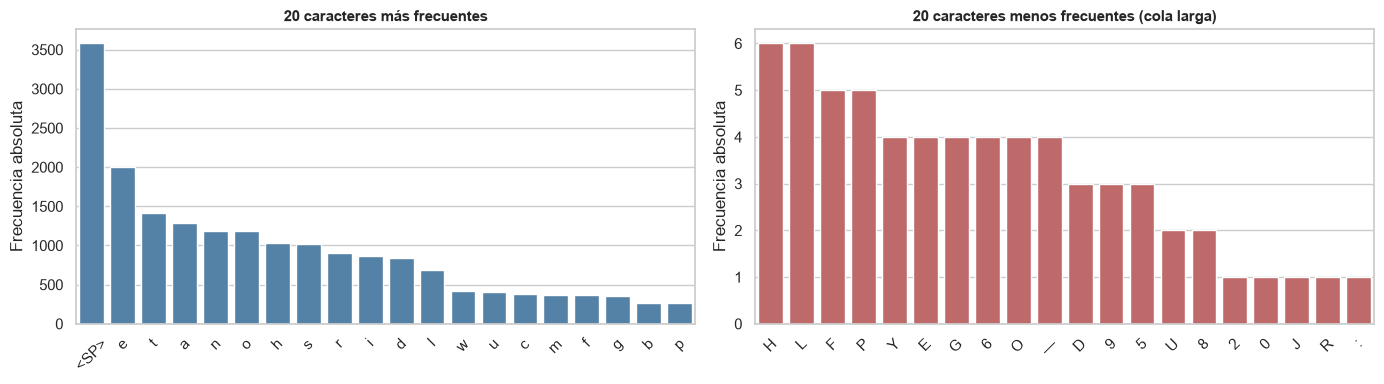

In [5]:
def vis(c):
    return {" ": "<SP>", "\n": "<NL>"}.get(str(c), str(c))

serie = pd.Series(char_counts).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

top20 = serie.head(20)
sns.barplot(x=[vis(c) for c in top20.index], y=top20.values, ax=axes[0], color="steelblue")
axes[0].set_title("20 caracteres más frecuentes", fontsize=11, fontweight="bold")
axes[0].set_ylabel("Frecuencia absoluta")
axes[0].tick_params(axis="x", rotation=45)

bottom20 = serie.tail(20)
sns.barplot(x=[vis(c) for c in bottom20.index], y=bottom20.values, ax=axes[1], color="indianred")
axes[1].set_title("20 caracteres menos frecuentes (cola larga)", fontsize=11, fontweight="bold")
axes[1].set_ylabel("Frecuencia absoluta")
axes[1].tick_params(axis="x", rotation=45)

plt.tight_layout()
plt.show()


### Gráfico 2: Distribución de longitud de palabras
Muestra cuán largas son las palabras que el modelo tiene que completar, un rasgo del estilo del texto.


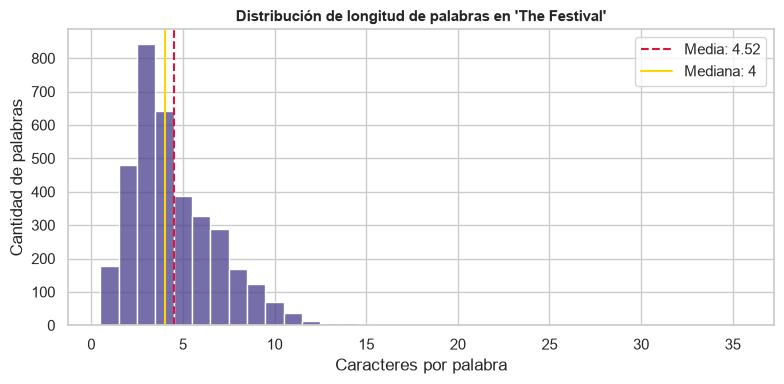

Palabras más largas del cuento: ['great-great-great-great-grandfather', 'phosphorescence', 'preternaturally', 'winter-whitened', 'spinning-wheel', 'undiscoverable']


In [6]:
plt.figure(figsize=(8, 4))
sns.histplot(word_lengths, bins=range(1, word_lengths.max() + 2), discrete=True, color="darkslateblue")
plt.axvline(word_lengths.mean(), color="crimson", linestyle="--", label=f"Media: {word_lengths.mean():.2f}")
plt.axvline(np.median(word_lengths), color="gold", linestyle="-", label=f"Mediana: {np.median(word_lengths):.0f}")
plt.title("Distribución de longitud de palabras en 'The Festival'", fontsize=11, fontweight="bold")
plt.xlabel("Caracteres por palabra")
plt.ylabel("Cantidad de palabras")
plt.legend()
plt.tight_layout()
plt.show()

largas = sorted({w for w in words if len(w) >= 14}, key=len, reverse=True)
print("Palabras más largas del cuento:", largas[:6])


### Gráfico 3: Frecuencia de signos de puntuación
Muestra qué signos aparecen y cuánto, porque el modelo también tiene que predecirlos.


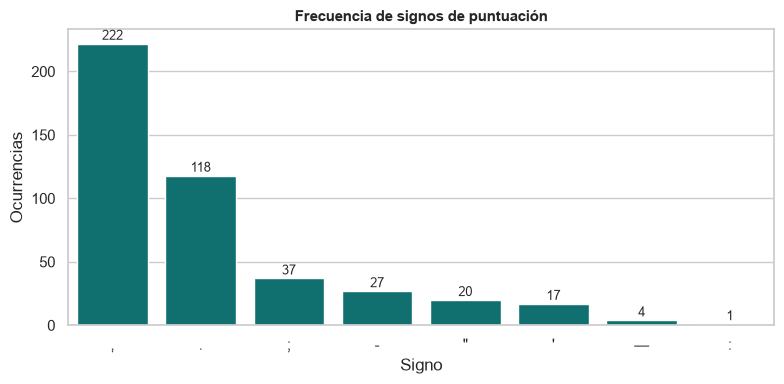

In [7]:
signos = set(".,;:!?'\"—-")
punct_counts = pd.Series([c for c in text if c in signos]).value_counts()

plt.figure(figsize=(8, 4))
sns.barplot(x=list(punct_counts.index), y=list(punct_counts.values), color="teal")
for i, n in enumerate(punct_counts.values):
    plt.text(i, n + 3, str(n), ha="center", fontsize=9)
plt.title("Frecuencia de signos de puntuación", fontsize=11, fontweight="bold")
plt.xlabel("Signo")
plt.ylabel("Ocurrencias")
plt.tight_layout()
plt.show()


### Diagnóstico de problemas potenciales: desbalance, outliers y estabilidad (data mismatch)
Revisamos tres problemas posibles (consigna 4.1.1):
1. **Desbalance de clases:** el espacio y algunas vocales, como la `'e'`, dominan el texto; otros caracteres aparecen muy poco.
2. **Clases raras (outliers):** caracteres con menos de 10 apariciones en todo el texto.
3. **Posible data mismatch:** comparamos la distribución de caracteres de la primera y la segunda mitad del cuento para ver si el estilo cambia.


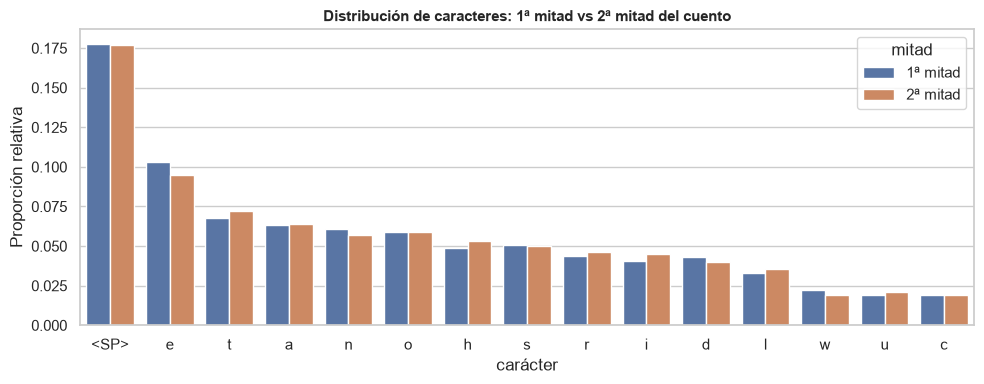

DIAGNÓSTICO DEL DATASET:
  • Desbalance: La clase mayoritaria '<SP>' representa el 17.7% del texto, mientras que ':' aparece solo 1 vez.
  • Outliers / Clases raras: 28 de 64 caracteres tienen menos de 10 apariciones: ['0', '1', '2', '5', '6', '8', '9', ':', 'B', 'C', 'D', 'E', 'F', 'G', 'H', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'R', 'U', 'W', 'Y', 'j', '—']
  • Estabilidad: Como muestra el gráfico comparativo, las frecuencias son sumamente estables entre mitades, descartando un data mismatch estilístico severo.


In [8]:
# Comparación de la 1ª mitad vs 2ª mitad del texto
mitad = len(text) // 2
c1, c2 = Counter(text[:mitad]), Counter(text[mitad:])
top15 = serie.index[:15]

df_mitades = pd.DataFrame({
    "carácter": [vis(c) for c in top15] * 2,
    "proporción": [c1[c] / mitad for c in top15] + [c2[c] / (len(text) - mitad) for c in top15],
    "mitad": ["1ª mitad"] * 15 + ["2ª mitad"] * 15
})

plt.figure(figsize=(10, 4))
sns.barplot(data=df_mitades, x="carácter", y="proporción", hue="mitad")
plt.title("Distribución de caracteres: 1ª mitad vs 2ª mitad del cuento", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout()
plt.show()

raros = [c for c, n in char_counts.items() if n < 10]
print("DIAGNÓSTICO DEL DATASET:")
print(f"  • Desbalance: La clase mayoritaria '{vis(serie.index[0])}' representa el {serie.iloc[0]/len(text)*100:.1f}% del texto, mientras que '{vis(serie.index[-1])}' aparece solo {serie.iloc[-1]} vez.")
print(f"  • Outliers / Clases raras: {len(raros)} de {vocab_size} caracteres tienen menos de 10 apariciones: {sorted(vis(c) for c in raros)}")
print("  • Estabilidad: Como muestra el gráfico comparativo, las frecuencias son sumamente estables entre mitades, descartando un data mismatch estilístico severo.")


---
# 2. Consigna 4.1.2: Partición de datos (Train / Dev / Test)

## 2.1 Por qué partimos por bloques
Las ventanas se generan con paso de 1 carácter, así que dos ventanas vecinas comparten 39 de sus 40 caracteres. Si las repartiéramos al azar con `train_test_split`, Dev tendría ejemplos casi idénticos a los de Train (**fuga de datos**).

**Estrategia: bloques contiguos (70% Train / 15% Dev / 15% Test)**
1. Dividimos el texto en bloques de ~400 caracteres.
2. Asignamos cada bloque completo al azar a Train, Dev o Test, con semilla fija.
3. Generamos las ventanas solo dentro de cada bloque.

Así no hay solapamiento entre conjuntos y los tres cubren todo el relato.


In [9]:
# ==============================================================================
# PARTICIÓN POR BLOQUES CONTIGUOS (70% Train / 15% Dev / 15% Test)
# ==============================================================================
L = 40        # Longitud de la ventana de contexto
BLOQUE = 400  # Caracteres por bloque contiguo

limites = [(i, min(i + BLOQUE, len(text))) for i in range(0, len(text), BLOQUE)]
if limites[-1][1] - limites[-1][0] < BLOQUE // 2:
    ini_prev = limites[-2][0]
    limites = limites[:-2] + [(ini_prev, len(text))]

n_bloques = len(limites)
rng = np.random.default_rng(SEED)
orden = rng.permutation(n_bloques)

n_tr = round(0.70 * n_bloques)
n_dev = round(0.15 * n_bloques)

bloques_split = {
    "train": sorted(orden[:n_tr].tolist()),
    "dev":   sorted(orden[n_tr:n_tr + n_dev].tolist()),
    "test":  sorted(orden[n_tr + n_dev:].tolist()),
}

def ventanas_de_bloques(ids):
    X, y = [], []
    for b in ids:
        ini, fin = limites[b]
        for i in range(ini, fin - L):
            X.append(text[i:i+L])
            y.append(text[i+L])
    return X, y

X_train, y_train = ventanas_de_bloques(bloques_split["train"])
X_dev,   y_dev   = ventanas_de_bloques(bloques_split["dev"])
X_test,  y_test  = ventanas_de_bloques(bloques_split["test"])

n_total = len(X_train) + len(X_dev) + len(X_test)
print(f"Bloques totales: {n_bloques} (~{BLOQUE} caracteres c/u) -> Train: {len(bloques_split['train'])} | Dev: {len(bloques_split['dev'])} | Test: {len(bloques_split['test'])}")
print(f"  • Train: {len(X_train):>6,} muestras ({len(X_train)/n_total*100:4.1f}%)")
print(f"  • Dev:   {len(X_dev):>6,} muestras ({len(X_dev)/n_total*100:4.1f}%)")
print(f"  • Test:  {len(X_test):>6,} muestras ({len(X_test)/n_total*100:4.1f}%)")
print(f"\nEjemplo extraído:\n  Contexto X: {X_train[0]!r}\n  Objetivo y: {y_train[0]!r}")


Bloques totales: 50 (~400 caracteres c/u) -> Train: 35 | Dev: 8 | Test: 7
  • Train: 12,780 muestras (70.3%)
  • Dev:    2,880 muestras (15.8%)
  • Test:   2,520 muestras (13.9%)

Ejemplo extraído:
  Contexto X: 'e tongue of the blue-eyed fishers. And n'
  Objetivo y: 'o'


## 2.2 Verificación de la distribución de clases en los tres conjuntos
Comprobamos que las proporciones de los caracteres objetivo sean parecidas en Train, Dev y Test.


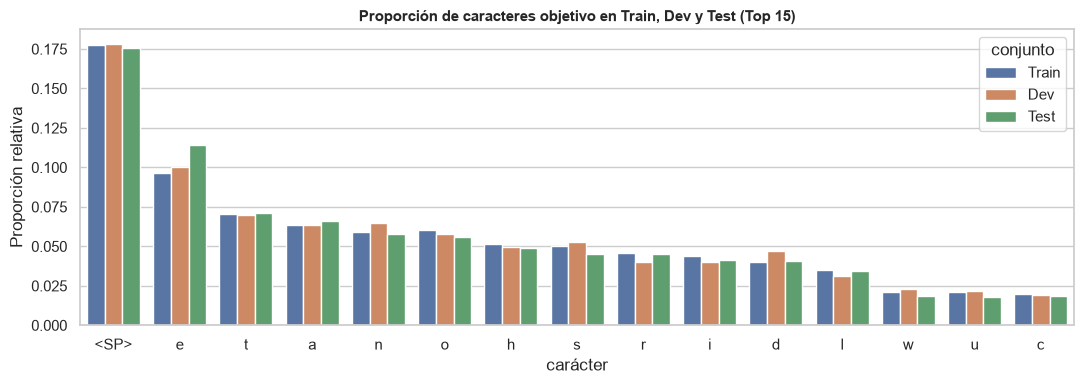

Caracteres en Dev/Test pero ausentes en Train: ['2']


In [10]:
conteos = {
    "Train": Counter(y_train),
    "Dev":   Counter(y_dev),
    "Test":  Counter(y_test),
}

freq = pd.DataFrame({s: pd.Series(c).reindex(vocabulary, fill_value=0) for s, c in conteos.items()})
prop = freq / freq.sum()

top15 = serie.index[:15]
df_p = prop.loc[top15].reset_index(names="carácter").melt(id_vars="carácter", var_name="conjunto", value_name="proporción")
df_p["carácter"] = df_p["carácter"].map(vis)

plt.figure(figsize=(11, 4))
sns.barplot(data=df_p, x="carácter", y="proporción", hue="conjunto")
plt.title("Proporción de caracteres objetivo en Train, Dev y Test (Top 15)", fontsize=11, fontweight="bold")
plt.ylabel("Proporción relativa")
plt.tight_layout()
plt.show()

sin_train = [vis(c) for c in vocabulary if freq.loc[c, "Train"] == 0 and (freq.loc[c, "Dev"] + freq.loc[c, "Test"]) > 0]
print(f"Caracteres en Dev/Test pero ausentes en Train: {sin_train}")


---
# 3. Consigna 4.1.3: Preprocesamiento y modelo baseline

## 3.1 Codificación numérica y persistencia de particiones
Definimos el mapeo entre caracteres y enteros (`char2idx` e `idx2char`) y guardamos el texto limpio y las particiones en `data/processed/`, para que todas las etapas usen exactamente los mismos datos.


In [11]:
# ==============================================================================
# CODIFICACIÓN NUMÉRICA Y PERSISTENCIA
# ==============================================================================
char2idx = {c: i for i, c in enumerate(vocabulary)}
idx2char = {i: c for c, i in char2idx.items()}
V = len(vocabulary)

OUT_DIR = BASE_DIR / "data" / "processed"
OUT_DIR.mkdir(parents=True, exist_ok=True)

(OUT_DIR / "The_Festival_clean.txt").write_text(text, encoding="utf-8")
with open(OUT_DIR / "splits_bloques.json", "w", encoding="utf-8") as f:
    json.dump({
        "L": L,
        "BLOQUE": BLOQUE,
        "SEED": SEED,
        "limites_bloques": limites,
        "bloques": bloques_split,
        "vocabulario": "".join(vocabulary)
    }, f, ensure_ascii=False)

print(f"Vocabulario (|V| = {V}) y particiones guardados exitosamente en {OUT_DIR.relative_to(BASE_DIR)}/")


Vocabulario (|V| = 64) y particiones guardados exitosamente en data\processed/


## 3.2 Métrica de número único
**Métrica elegida: accuracy top-1 en Dev** (proporción de caracteres acertados).

- **Por qué:** es fácil de interpretar y se compara directamente con la referencia trivial de predecir siempre el carácter más frecuente (el espacio).
- Es el número que tienen que superar los modelos de las etapas siguientes.


In [12]:
# ==============================================================================
# REFERENCIA TRIVIAL: PREDICCIÓN DE LA CLASE MAYORITARIA
# ==============================================================================
clase_mayoritaria = serie.index[0]
acc_dummy_dev = np.mean([y == clase_mayoritaria for y in y_dev])

print(f"Clase mayoritaria en el texto: '{vis(clase_mayoritaria)}'")
print(f"Accuracy de referencia trivial en Dev: {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")


Clase mayoritaria en el texto: '<SP>'
Accuracy de referencia trivial en Dev: 0.1785 (17.85%)


## 3.3 Baseline: regresión logística sobre los últimos $K$ caracteres
Los caracteres justo anteriores son los que más informan sobre el siguiente, así que el baseline usa solo esos:
1. Tomamos los últimos $K$ caracteres de la ventana.
2. Los codificamos con `OneHotEncoder`.
3. Entrenamos una `LogisticRegression` multinomial (equivale a una red de una sola capa densa con softmax).

Probamos $K \in \{1, 3, 5\}$ y elegimos el mejor según Dev.


   Accuracy Train  Accuracy Dev  Tiempo (s)
K                                          
1          0.3005        0.3122      1.0333
3          0.4026        0.4069      1.3315
5          0.4297        0.4083      1.5263

Mejor K seleccionado con Dev: K = 5


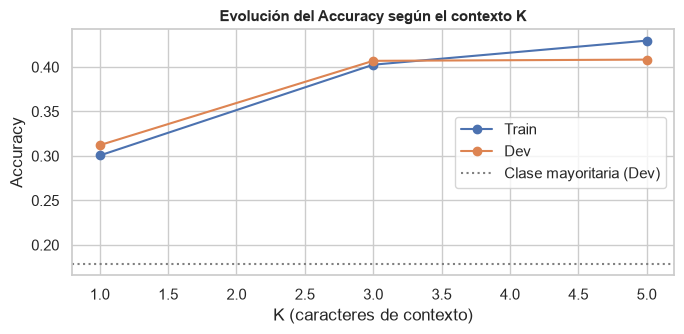

In [13]:
# ==============================================================================
# ENTRENAMIENTO DEL BASELINE CON VARIACIÓN DE CONTEXTO K
# ==============================================================================
def ultimos(X, k):
    return np.array([list(x[-k:]) for x in X])

resultados_k = []
modelos_k = {}
tiempos_k = {}

for k in [1, 3, 5]:
    pipe = Pipeline([
        ("onehot", OneHotEncoder(handle_unknown="ignore")),
        ("clf", LogisticRegression(max_iter=500, random_state=SEED)),
    ])
    t0 = time.perf_counter()
    with warnings.catch_warnings():
        warnings.simplefilter("ignore")
        pipe.fit(ultimos(X_train, k), y_train)
    tiempos_k[k] = time.perf_counter() - t0
    
    modelos_k[k] = pipe
    acc_tr = accuracy_score(y_train, pipe.predict(ultimos(X_train, k)))
    acc_dev = accuracy_score(y_dev, pipe.predict(ultimos(X_dev, k)))
    resultados_k.append({"K": k, "Accuracy Train": acc_tr, "Accuracy Dev": acc_dev, "Tiempo (s)": tiempos_k[k]})

df_k = pd.DataFrame(resultados_k).set_index("K")
print(df_k.round(4))

K_OPTIMO = int(df_k["Accuracy Dev"].idxmax())
print(f"\nMejor K seleccionado con Dev: K = {K_OPTIMO}")

plt.figure(figsize=(7, 3.5))
plt.plot(df_k.index, df_k["Accuracy Train"], marker="o", label="Train")
plt.plot(df_k.index, df_k["Accuracy Dev"], marker="o", label="Dev")
plt.axhline(acc_dummy_dev, color="gray", linestyle=":", label="Clase mayoritaria (Dev)")
plt.xlabel("K (caracteres de contexto)")
plt.ylabel("Accuracy")
plt.title("Evolución del Accuracy según el contexto K", fontsize=11, fontweight="bold")
plt.legend()
plt.tight_layout()
plt.show()


## 3.4 Resultado del baseline en Dev
Reportamos el resultado del baseline en Dev (consigna 4.1.3): es la referencia que tienen que superar los modelos de las etapas siguientes. También medimos la accuracy en Train, la pérdida, la perplejidad, los parámetros y el tiempo de entrenamiento, que se usan en la Etapa 2 y en la tabla final de la Etapa 5.


In [14]:
# ==============================================================================
# REPORTE OFICIAL DEL BASELINE EN DEV (Consigna 4.1.3)
# ==============================================================================
baseline_final = modelos_k[K_OPTIMO]
Xdev_opt = ultimos(X_dev, K_OPTIMO)
y_pred_dev = baseline_final.predict(Xdev_opt)

acc_base_dev = accuracy_score(y_dev, y_pred_dev)

# Métricas complementarias, medidas aquí para no fijarlas a mano en etapas posteriores
acc_base_train = accuracy_score(y_train, baseline_final.predict(ultimos(X_train, K_OPTIMO)))

def perdida_log(pipe, X_k, y_real):
    """Entropía cruzada media. Si un carácter real no está entre las clases del modelo, recibe probabilidad 1e-15."""
    proba = pipe.predict_proba(X_k)
    col = {c: j for j, c in enumerate(pipe.classes_)}
    p_real = np.array([proba[i, col[c]] if c in col else 1e-15 for i, c in enumerate(y_real)])
    return float(-np.mean(np.log(np.clip(p_real, 1e-15, 1.0))))

loss_base_dev = perdida_log(baseline_final, Xdev_opt, y_dev)
perp_base_dev = float(np.exp(loss_base_dev))
clf_base = baseline_final.named_steps["clf"]
params_base = int(clf_base.coef_.size + clf_base.intercept_.size)
tiempo_base = tiempos_k[K_OPTIMO]

print("=" * 70)
print(f"BASELINE OFICIAL — One-Hot últimos {K_OPTIMO} caracteres + Regresión Logística:")
print(f"  • Accuracy en Dev: {acc_base_dev:.4f} ({acc_base_dev*100:.2f}%)")
print(f"  • Referencia trivial (clase mayoritaria): {acc_dummy_dev:.4f} ({acc_dummy_dev*100:.2f}%)")
print(f"  • Ganancia sobre la referencia trivial: +{(acc_base_dev - acc_dummy_dev)*100:.2f} puntos porcentuales")
print(f"  • Muestras evaluadas en Dev: {len(y_dev)}")
print(f"  • Accuracy en Train: {acc_base_train*100:.2f}% (brecha Train - Dev: {(acc_base_train - acc_base_dev)*100:.2f} pp)")
print(f"  • Pérdida (entropía cruzada) en Dev: {loss_base_dev:.4f} | Perplejidad en Dev: {perp_base_dev:.2f}")
print(f"  • Parámetros entrenables: {params_base:,} | Tiempo de entrenamiento: {tiempo_base:.2f} s")
print("=" * 70)

# Guardar en disco para referencia futura en Etapa 2 y 5
with open(OUT_DIR / "baseline_dev.json", "w", encoding="utf-8") as f:
    json.dump({
        "modelo": f"OneHot_ultimos_{K_OPTIMO}_chars + LogisticRegression",
        "K": K_OPTIMO,
        "metrica_principal": "accuracy_dev",
        "accuracy_dev": float(acc_base_dev),
        "accuracy_train": float(acc_base_train),
        "loss_dev": loss_base_dev,
        "perplejidad_dev": perp_base_dev,
        "parametros_entrenables": params_base,
        "tiempo_entrenamiento_s": tiempo_base,
        "accuracy_dummy_dev": float(acc_dummy_dev),
        "n_dev": len(y_dev)
    }, f, indent=2)
print("Métrica oficial guardada en data/processed/baseline_dev.json")


BASELINE OFICIAL — One-Hot últimos 5 caracteres + Regresión Logística:
  • Accuracy en Dev: 0.4083 (40.83%)
  • Referencia trivial (clase mayoritaria): 0.1785 (17.85%)
  • Ganancia sobre la referencia trivial: +22.99 puntos porcentuales
  • Muestras evaluadas en Dev: 2880
  • Accuracy en Train: 42.97% (brecha Train - Dev: 2.13 pp)
  • Pérdida (entropía cruzada) en Dev: 2.0853 | Perplejidad en Dev: 8.05
  • Parámetros entrenables: 19,908 | Tiempo de entrenamiento: 1.53 s
Métrica oficial guardada en data/processed/baseline_dev.json


## 3.5 Matriz de confusión del baseline
Miramos la matriz de confusión normalizada de los 20 caracteres más frecuentes para ver con qué se confunde el modelo.


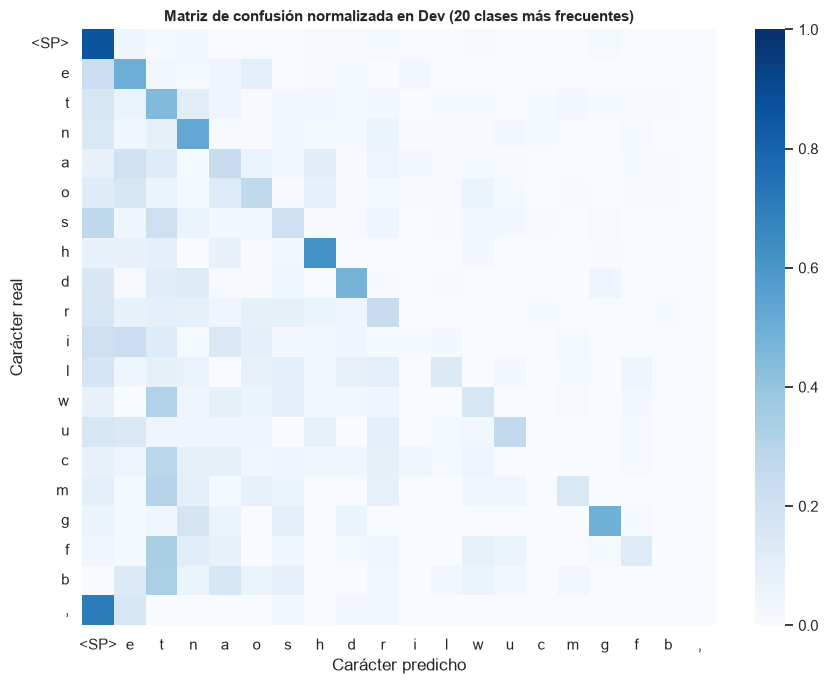

Total de errores en Dev: 1704 de 2880

Pares de caracteres más confundidos (real -> predicho):
Real Predicho  Ocurrencias
   e     <SP>           65
   s     <SP>           42
   a        e           37
   t     <SP>           33
   s        t           33
   n     <SP>           28
   e        o           28
   o        e           27


In [15]:
# ==============================================================================
# MATRIZ DE CONFUSIÓN Y ANÁLISIS DE ERRORES EN DEV
# ==============================================================================
labels_all = sorted(set(y_dev) | set(y_pred_dev))
cm = confusion_matrix(y_dev, y_pred_dev, labels=labels_all, normalize="true")

top20 = [c for c, _ in Counter(y_dev).most_common(20)]
ix = [labels_all.index(c) for c in top20]

plt.figure(figsize=(9, 7))
sns.heatmap(cm[np.ix_(ix, ix)], cmap="Blues", vmin=0, vmax=1,
            xticklabels=[vis(c) for c in top20], yticklabels=[vis(c) for c in top20])
plt.title("Matriz de confusión normalizada en Dev (20 clases más frecuentes)", fontsize=11, fontweight="bold")
plt.xlabel("Carácter predicho")
plt.ylabel("Carácter real")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

errores = [(r, p) for r, p in zip(y_dev, y_pred_dev) if r != p]
top_errores = Counter(errores).most_common(8)
print(f"Total de errores en Dev: {len(errores)} de {len(y_dev)}")
print("\nPares de caracteres más confundidos (real -> predicho):")
df_err = pd.DataFrame([(vis(r), vis(p), n) for (r, p), n in top_errores], columns=["Real", "Predicho", "Ocurrencias"])
print(df_err.to_string(index=False))


---
# 4. Síntesis y checklist de la Etapa 1
Estado de cada requisito de la consigna.


In [16]:
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 1")
print(f"  [x] 4.1.1 Carga y EDA: {len(text):,} caracteres, |V| = {vocab_size}, 3 gráficos descriptivos y diagnóstico de problemas.")
print(f"  [x] 4.1.2 Partición: Train ({len(X_train):,}) / Dev ({len(X_dev):,}) / Test ({len(X_test):,}) mediante bloques contiguos sin data leakage.")
print("  [x] 4.1.2 Proporción de clases verificada en los tres conjuntos.")
print(f"  [x] 4.1.3 Preprocesamiento y Baseline: One-Hot de últimos {K_OPTIMO} caracteres + Regresión Logística multinomial.")
print(f"  [x] 4.1.3 Métrica de número único: Accuracy en Dev = {acc_base_dev:.4f} (referencia trivial = {acc_dummy_dev:.4f}).")
print("  [x] Particiones, vocabulario y baseline guardados en data/processed/ para la Etapa 2.")
print("  [x] Conjunto Test preservado estrictamente intacto para la evaluación final en la Etapa 5.")


CHECKLIST DE CUMPLIMIENTO - ETAPA 1
  [x] 4.1.1 Carga y EDA: 20,180 caracteres, |V| = 64, 3 gráficos descriptivos y diagnóstico de problemas.
  [x] 4.1.2 Partición: Train (12,780) / Dev (2,880) / Test (2,520) mediante bloques contiguos sin data leakage.
  [x] 4.1.2 Proporción de clases verificada en los tres conjuntos.
  [x] 4.1.3 Preprocesamiento y Baseline: One-Hot de últimos 5 caracteres + Regresión Logística multinomial.
  [x] 4.1.3 Métrica de número único: Accuracy en Dev = 0.4083 (referencia trivial = 0.1785).
  [x] Particiones, vocabulario y baseline guardados en data/processed/ para la Etapa 2.
  [x] Conjunto Test preservado estrictamente intacto para la evaluación final en la Etapa 5.


---
# 5. Etapa 2: Red neuronal multicapa (MLP) y regularización

En esta etapa analizamos los errores del baseline, entrenamos un MLP para reducir su sesgo y aplicamos regularización para controlar el sobreajuste que aparece.

### Decisiones de la Etapa 2
1. **Misma entrada que el baseline ($K = 5$, 320 valores one-hot):** así la diferencia de rendimiento se debe principalmente a la red y no a tener más información.
2. **TensorFlow / Keras (`tf.keras`)** para todos los modelos neuronales del TP.
3. **5 semillas fijas** (`SEEDS = [42, 123, 456, 789, 2026]`): con 2.880 muestras en Dev, el margen de error de una medición es de unos $\pm 1,8$ pp, así que una sola corrida no alcanza para comparar modelos. Reportamos media ± desvío.
4. **Errores clasificados con reglas fijas:** para que la asignación de causas sea reproducible y no dependa de quién mira el caso.
5. **Grilla + ablación:** elegimos los hiperparámetros con una grilla en Dev y entrenamos cada técnica por separado y combinada, para saber cuánto aporta cada una.
6. **Test intacto** hasta la Etapa 5.


In [17]:
# ==============================================================================
# 5.1 CONFIGURACIÓN DE TENSORFLOW/KERAS Y PREPARACIÓN DE TENSORES
# ==============================================================================
import os
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "2"  # Ocultar mensajes de bajo nivel de C++
os.environ["KERAS_HOME"] = os.path.abspath(os.path.join(os.getcwd(), "..", "..", ".keras"))

import time
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers, regularizers, callbacks

print(f"TensorFlow Version: {tf.__version__}")
print(f"Keras Version:      {keras.__version__}")

# Semillas fijas para la evaluación multi-semilla
SEEDS = [42, 123, 456, 789, 2026]

# ------------------------------------------------------------------------------
# Transformación a tensores densos One-Hot aplanados (N, K * |V|) = (N, 320)
# Cada posición se codifica en un vector binario de dimensión |V| = 64
# ------------------------------------------------------------------------------
def extraer_tensores_onehot(X_raw, y_raw, k, c2i, v_size):
    N = len(X_raw)
    X_oh = np.zeros((N, k * v_size), dtype=np.float32)
    y_idx = np.array([c2i[c] for c in y_raw], dtype=np.int32)
    
    for i, seq in enumerate(X_raw):
        ctx_k = seq[-k:]
        for pos, char in enumerate(ctx_k):
            c_idx = c2i[char]
            X_oh[i, pos * v_size + c_idx] = 1.0
            
    return X_oh, y_idx

X_train_oh, y_train_idx = extraer_tensores_onehot(X_train, y_train, K_OPTIMO, char2idx, vocab_size)
X_dev_oh, y_dev_idx     = extraer_tensores_onehot(X_dev, y_dev, K_OPTIMO, char2idx, vocab_size)

print("\nDimensiones de los tensores generados para Keras:")
print(f"  • X_train_oh: {X_train_oh.shape}  | y_train_idx: {y_train_idx.shape}")
print(f"  • X_dev_oh:   {X_dev_oh.shape}   | y_dev_idx:   {y_dev_idx.shape}")
print(f"  • Features por muestra: {X_train_oh.shape[1]} ({K_OPTIMO} caracteres * {vocab_size} clases)")


TensorFlow Version: 2.21.0
Keras Version:      3.15.1

Dimensiones de los tensores generados para Keras:
  • X_train_oh: (12780, 320)  | y_train_idx: (12780,)
  • X_dev_oh:   (2880, 320)   | y_dev_idx:   (2880,)
  • Features por muestra: 320 (5 caracteres * 64 clases)


---
# 6. Consigna 4.2.1: Análisis manual de errores del baseline

Separamos los errores según su causa, siguiendo *Machine Learning Yearning* (Andrew Ng), porque cada causa se corrige con una acción distinta:
- **Ruido irreducible:** con 5 caracteres de contexto a veces hay varias continuaciones válidas (por ejemplo, después de `"the "`). Ningún modelo con ese contexto las acierta siempre.
- **Sesgo (underfitting):** el modelo no aprende patrones que están en los datos. Se corrige con un modelo más expresivo.
- **Varianza (overfitting):** el modelo aprende detalles de Train que no se repiten en Dev. Se corrige con más datos o con regularización.
- **Data mismatch:** Train y Dev vienen de distribuciones distintas. En la Etapa 1 la distribución de caracteres es estable entre las dos mitades del cuento y las proporciones son parecidas en los tres conjuntos (solo el carácter `2` aparece en Dev/Test y no en Train), así que no esperamos errores de este tipo.

### Reglas para asignar la causa (en orden de precedencia)
Para cada error de Dev miramos su contexto de 5 caracteres y aplicamos la primera regla que se cumpla:
1. **Falta de cobertura:** el contexto nunca aparece en Train. El modelo no vio esa combinación.
2. **Ruido irreducible:** el contexto aparece en Train seguido de varios caracteres distintos y el real no es el más frecuente. Incluso eligiendo siempre el más frecuente se fallaría.
3. **Sesgo:** el contexto aparece en Train y el baseline también falla ahí la mayoría de las veces (acierto $\le 50\%$). Tiene datos, pero no aprendió el patrón.
4. **Varianza:** el contexto aparece en Train y el baseline acierta ahí (acierto $> 50\%$), pero falla en Dev.

Además registramos el tipo de error (espacio, vocales, mayúsculas, etc.) en una columna aparte.


Total de errores del baseline en Dev: 1704 de 2880 (Tasa de error = 59.17%)


C:\Users\Leonardo\AppData\Local\Temp\ipykernel_21636\1615563601.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=causas_cnt, x="Casos", y="Causa", ax=axes[0], palette="Blues_r")
C:\Users\Leonardo\AppData\Local\Temp\ipykernel_21636\1615563601.py:81: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=ling_cnt, x="Casos", y="Categoría", ax=axes[1], palette="Reds_r")


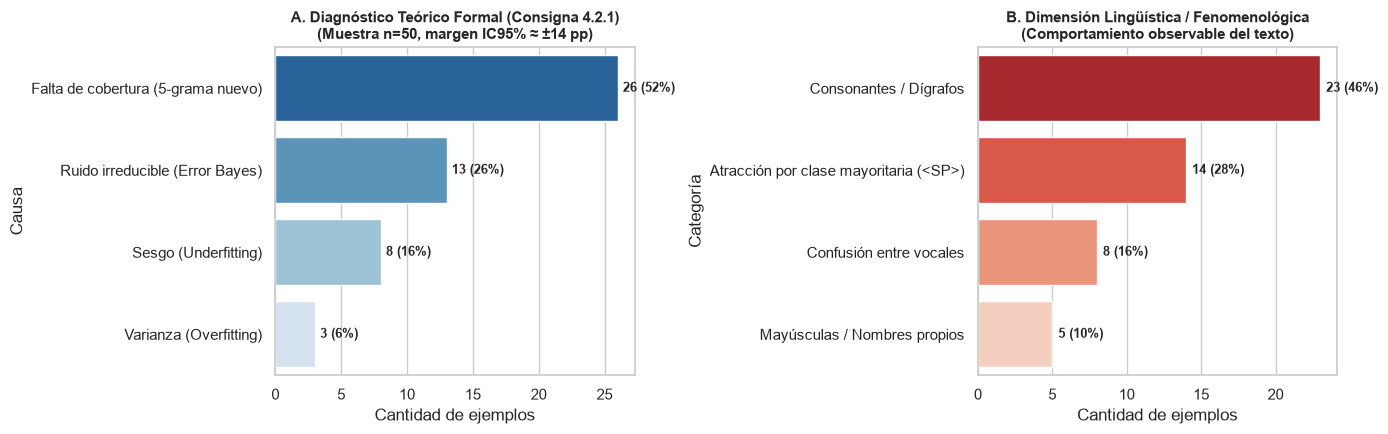

,Contexto (5 chars),Target Real,Pred. Baseline,Causa Teórica (ML),Categoría Lingüística
1046,g. Af,t,<SP>,Falta de cobertura (5-grama nuevo),Atracción por clase mayoritaria (<SP>)
745,and,a,t,Ruido irreducible (Error Bayes),Consonantes / Dígrafos
785,ied.,H,T,Falta de cobertura (5-grama nuevo),Mayúsculas / Nombres propios
367,old,P,m,Ruido irreducible (Error Bayes),Mayúsculas / Nombres propios
1029,e age,d,<SP>,Falta de cobertura (5-grama nuevo),Atracción por clase mayoritaria (<SP>)
1648,a na,s,t,Sesgo (Underfitting),Consonantes / Dígrafos
259,"692,",b,t,Falta de cobertura (5-grama nuevo),Consonantes / Dígrafos
1509,e I c,o,a,Sesgo (Underfitting),Confusión entre vocales
514,in m,e,a,Falta de cobertura (5-grama nuevo),Confusión entre vocales
1229,that,c,<SP>,Ruido irreducible (Error Bayes),Atracción por clase mayoritaria (<SP>)


In [18]:
# ==============================================================================
# 6.1 ANÁLISIS DE ERRORES DETERMINÍSTICO Y MUESTREO DE 50 CASOS (Consigna 4.2.1)
# ==============================================================================
# Predicciones del Baseline K=5 en Train y Dev
best_pipe = modelos_k[K_OPTIMO]
y_pred_tr_base  = best_pipe.predict(ultimos(X_train, K_OPTIMO))
y_pred_dev_base = best_pipe.predict(ultimos(X_dev, K_OPTIMO))

ctx_train_k = ["".join(x) for x in ultimos(X_train, K_OPTIMO)]
ctx_dev_k   = ["".join(x) for x in ultimos(X_dev, K_OPTIMO)]

from collections import defaultdict
ctx_train_stats = defaultdict(list)
for ctx, yr, yp in zip(ctx_train_k, y_train, y_pred_tr_base):
    ctx_train_stats[ctx].append((yr, yp))

# Filtrar todos los errores en Dev
errores_dev = []
for idx, (ctx, yr, yp) in enumerate(zip(ctx_dev_k, y_dev, y_pred_dev_base)):
    if yr != yp:
        errores_dev.append({
            "dev_idx": idx,
            "contexto": ctx,
            "y_real": yr,
            "y_pred": yp
        })

print(f"Total de errores del baseline en Dev: {len(errores_dev)} de {len(y_dev)} (Tasa de error = {len(errores_dev)/len(y_dev)*100:.2f}%)")

# Funciones de clasificación con orden de precedencia documentado
def clasificar_causa_teorica(ctx, yr, yp):
    if ctx not in ctx_train_stats:
        return "Falta de cobertura (5-grama nuevo)"
    ocurr = ctx_train_stats[ctx]
    targets = [t[0] for t in ocurr]
    conteo = Counter(targets)
    moda = conteo.most_common(1)[0][0]
    if len(conteo) > 1 and yr != moda:
        return "Ruido irreducible (Error Bayes)"
    aciertos = sum(1 for t, p in ocurr if t == p)
    if (aciertos / len(ocurr)) <= 0.5:
        return "Sesgo (Underfitting)"
    return "Varianza (Overfitting)"

def clasificar_fenomeno_linguistico(yr, yp):
    if yp == ' ':
        return "Atracción por clase mayoritaria (<SP>)"
    if yr == ' ':
        return "Fin de palabra no detectado (omisión <SP>)"
    if yr.lower() in "aeiou" and yp.lower() in "aeiou":
        return "Confusión entre vocales"
    if yr.isupper() or yp.isupper():
        return "Mayúsculas / Nombres propios"
    if yr in ".-,;:!?'\"—" or yp in ".-,;:!?'\"—":
        return "Puntuación / Delimitadores"
    return "Consonantes / Dígrafos"

for e in errores_dev:
    e["causa_teorica"] = clasificar_causa_teorica(e["contexto"], e["y_real"], e["y_pred"])
    e["categoria_ling"] = clasificar_fenomeno_linguistico(e["y_real"], e["y_pred"])

df_errores_all = pd.DataFrame(errores_dev)

# Muestra aleatoria de 50 errores con semilla fija
df_50_muestra = df_errores_all.sample(n=50, random_state=SEED).copy()
df_50_muestra.to_csv(os.path.join("..", "data", "processed", "muestra_50_errores_dev.csv"), index=False, encoding="utf-8")

# Visualización de los 50 errores clasificados
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

causas_cnt = df_50_muestra["causa_teorica"].value_counts().reset_index()
causas_cnt.columns = ["Causa", "Casos"]
sns.barplot(data=causas_cnt, x="Casos", y="Causa", ax=axes[0], palette="Blues_r")
axes[0].set_title("A. Diagnóstico Teórico Formal (Consigna 4.2.1)\n(Muestra n=50, margen IC95% ≈ ±14 pp)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Cantidad de ejemplos")
for i, v in enumerate(causas_cnt["Casos"]):
    axes[0].text(v + 0.4, i, f"{v} ({v*2}%)", va="center", fontsize=9, fontweight="bold")

ling_cnt = df_50_muestra["categoria_ling"].value_counts().reset_index()
ling_cnt.columns = ["Categoría", "Casos"]
sns.barplot(data=ling_cnt, x="Casos", y="Categoría", ax=axes[1], palette="Reds_r")
axes[1].set_title("B. Dimensión Lingüística / Fenomenológica\n(Comportamiento observable del texto)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Cantidad de ejemplos")
for i, v in enumerate(ling_cnt["Casos"]):
    axes[1].text(v + 0.4, i, f"{v} ({v*2}%)", va="center", fontsize=9, fontweight="bold")

plt.tight_layout()
plt.show()

# Mostrar primeros 10 casos en tabla formateada
def vis_c(c): return "<SP>" if c == " " else str(c)
df_disp = df_50_muestra[["contexto", "y_real", "y_pred", "causa_teorica", "categoria_ling"]].head(10).copy()
df_disp["y_real"] = df_disp["y_real"].map(vis_c)
df_disp["y_pred"] = df_disp["y_pred"].map(vis_c)
df_disp.columns = ["Contexto (5 chars)", "Target Real", "Pred. Baseline", "Causa Teórica (ML)", "Categoría Lingüística"]
df_disp


### 6.2 Diagnóstico de sesgo y varianza del baseline

| Conjunto | Accuracy | Error |
|---|---|---|
| Train | $42,97\%$ | $57,03\%$ |
| Dev | $40,83\%$ | $59,17\%$ |

La brecha Train–Dev es chica ($2,13$ pp), pero el error es alto en los dos conjuntos: el baseline tiene **sesgo alto (underfitting)**, no sobreajuste. Un modelo lineal sobre one-hot no puede capturar interacciones entre las posiciones del contexto.

**Acción:** pasar a un MLP, que sí puede capturarlas. Como tiene $53.536$ parámetros para $12.780$ muestras, esperamos que aparezca **varianza**, y por eso en la sección 8 agregamos regularización.

**Cuánto sesgo se puede corregir:** lo estimamos en la sección 8.5 con los MLP ya entrenados. No usamos el MLP sin regularizar como referencia porque memoriza Train: su error de Train puede quedar por debajo del mínimo posible y exagerar la estimación.


### 6.3 Accuracy por tipo de carácter
Separamos la accuracy según el tipo del carácter real: **espacio**, **vocal** minúscula, **consonante** minúscula, **mayúscula** y **puntuación/dígito**. Así vemos dónde se concentran los errores del baseline y, en la sección 8.4, dónde mejora el MLP.


In [19]:
# ==============================================================================
# 6.3 ACCURACY POR TIPO DE CARÁCTER EN DEV
# ==============================================================================
TIPOS_CHAR = ["espacio", "vocal", "consonante", "mayúscula", "puntuación/dígito"]

def tipo_caracter(c):
    if c == " ":
        return "espacio"
    if c.isupper():
        return "mayúscula"
    if c in "aeiou":
        return "vocal"
    if c.isalpha():
        return "consonante"
    return "puntuación/dígito"

tipos_dev = np.array([tipo_caracter(c) for c in y_dev])

def accuracy_por_tipo(y_pred, y_real=y_dev, tipos=tipos_dev):
    """Accuracy separada por tipo de carácter real, más la accuracy global."""
    y_pred, y_real = np.asarray(y_pred), np.asarray(y_real)
    res = {t: (y_pred[tipos == t] == y_real[tipos == t]).mean() for t in TIPOS_CHAR}
    res["global"] = (y_pred == y_real).mean()
    return res

soporte_tipos = pd.Series(tipos_dev).value_counts().reindex(TIPOS_CHAR)
df_tipos_base = pd.DataFrame({
    "Casos en Dev": soporte_tipos,
    "% de Dev": (soporte_tipos / len(y_dev) * 100).round(1),
    "Accuracy Baseline": pd.Series(accuracy_por_tipo(y_pred_dev_base)).reindex(TIPOS_CHAR).round(4),
})
df_tipos_base


,Casos en Dev,% de Dev,Accuracy Baseline
espacio,514,17.8,0.8580
vocal,817,28.4,0.3060
consonante,1451,50.4,0.3280
mayúscula,38,1.3,0.1842
puntuación/dígito,60,2.1,0.0333


**Interpretación.** El baseline acierta el $85,8\%$ de los espacios, pero solo el $30,6\%$ de las vocales y el $32,8\%$ de las consonantes, que juntas son el $78,8\%$ de Dev. Lo difícil no es saber cuándo termina una palabra sino elegir la letra dentro de ella, y ahí es donde tiene que mejorar el MLP. Parte del acierto en espacios se explica porque el baseline tiende a predecirlos: en 14 de los 50 errores de la muestra predijo un espacio que no correspondía. En mayúsculas ($18,4\%$) y puntuación/dígitos ($3,3\%$) casi no acierta, pero son pocos casos (38 y 60).


### 6.4 Explicación de predicciones individuales
La función `explicar_prediccion` muestra los 5 caracteres más probables para un contexto y en qué puesto quedó el real. La aplicamos a un error de cada causa. Sirve para distinguir causas: si el real queda 2.º con una probabilidad parecida a la del 1.º, apunta a ruido irreducible; si tiene probabilidad casi nula, el modelo no aprendió el patrón.


In [20]:
# ==============================================================================
# 6.4 EXPLICACIÓN DE PREDICCIONES
# ==============================================================================
def proba_baseline(contextos):
    """Matriz (n, |V|) de probabilidades del baseline, en el orden de char2idx."""
    proba = best_pipe.predict_proba(ultimos(contextos, K_OPTIMO))
    salida = np.zeros((len(contextos), vocab_size))
    for j, c in enumerate(best_pipe.classes_):
        salida[:, char2idx[c]] = proba[:, j]
    return salida

def explicar_prediccion(proba_fn, contexto, y_real, nombre_modelo, top=5):
    """Imprime el top de caracteres más probables y el puesto que ocupa el carácter real."""
    p = proba_fn([contexto])[0]
    orden = np.argsort(p)[::-1]
    puesto_real = int(np.where(orden == char2idx[y_real])[0][0]) + 1
    print(f"  [{nombre_modelo}] contexto '...{contexto[-20:]}' | real '{vis_c(y_real)}' "
          f"en el puesto {puesto_real} (P = {p[char2idx[y_real]]:.3f})")
    print("     top-" + str(top) + ": " + " | ".join(f"'{vis_c(idx2char[j])}' {p[j]:.3f}" for j in orden[:top]))

# Un caso de cada causa (pre-etiqueta por reglas) de la muestra de 50 errores
casos_ejemplo = df_50_muestra.groupby("causa_teorica", sort=False).head(1)
for _, fila in casos_ejemplo.iterrows():
    print(f"Causa (pre-etiqueta por reglas): {fila['causa_teorica']}")
    explicar_prediccion(proba_baseline, X_dev[fila["dev_idx"]], fila["y_real"], "Baseline")
    print()


Causa (pre-etiqueta por reglas): Falta de cobertura (5-grama nuevo)
  [Baseline] contexto '...ad been striking. Af' | real 't' en el puesto 4 (P = 0.074)
     top-5: '<SP>' 0.503 | 'a' 0.102 | 'o' 0.100 | 't' 0.074 | 'l' 0.048

Causa (pre-etiqueta por reglas): Ruido irreducible (Error Bayes)
  [Baseline] contexto '... wrote a quaint and ' | real 'a' en el puesto 4 (P = 0.090)
     top-5: 't' 0.147 | 'w' 0.140 | 's' 0.095 | 'a' 0.090 | 'h' 0.059

Causa (pre-etiqueta por reglas): Sesgo (Underfitting)
  [Baseline] contexto '...tone above with a na' | real 's' en el puesto 3 (P = 0.088)
     top-5: 't' 0.160 | 'd' 0.127 | 's' 0.088 | 'l' 0.087 | '<SP>' 0.086

Causa (pre-etiqueta por reglas): Varianza (Overfitting)
  [Baseline] contexto '...ersons on the settle' | real ',' en el puesto 3 (P = 0.054)
     top-5: '<SP>' 0.708 | 'n' 0.055 | ',' 0.054 | 's' 0.045 | 'e' 0.019



**Interpretación.** En los cuatro casos el carácter real está entre los 4 más probables y nunca tiene probabilidad casi nula: el baseline no se equivoca por completo, sino que reparte mal la probabilidad.
- **Ruido irreducible** (`" and "` → `a`): la distribución es plana, con los 4 primeros entre $0,09$ y $0,15$. Ese contexto admite muchas continuaciones, así que el error es esperable.
- **Falta de cobertura** (`"g. Af"` → `t`): como no vio ese 5-grama, apuesta al espacio, la clase más frecuente ($0,503$).
- **Varianza** (`"ettle"` → `,`): pasa algo parecido, apuesta fuerte al espacio ($0,708$) y la coma queda 3.ª.
- **Sesgo** (`" a na"` → `s`): el real queda 3.º ($0,088$), cerca del 1.º (`t`, $0,160$).

Son 4 casos: sirven como ilustración, no como conteo.


---
# 7. Consigna 4.2.2: Arquitectura MLP

Usamos un MLP chico con **3 capas ocultas** decrecientes y la misma entrada que el baseline ($K = 5$), para que la comparación mida el efecto de la red.

### Arquitectura
| Componente | Elección |
|---|---|
| Entrada | $320$ valores ($5 \times 64$, one-hot aplanado) |
| Capas ocultas | Dense(128) → Dense(64) → Dense(32), activación ReLU |
| Salida | Dense(64) con softmax: una probabilidad por carácter |
| Pérdida | Entropía cruzada (`sparse_categorical_crossentropy`, con etiquetas enteras) |
| Optimizador | Adam, learning rate $0,001$ |
| Batch size / épocas | $128$ / $40$ |

Usamos softmax con entropía cruzada porque la salida es una distribución de probabilidad sobre los 64 caracteres.

### Parámetros entrenables
* Capa 1: $(320 \times 128) + 128 = 40.960 + 128 = 41.088$
* Capa 2: $(128 \times 64) + 64 = 8.192 + 64 = 8.256$
* Capa 3: $(64 \times 32) + 32 = 2.048 + 32 = 2.080$
* Capa 4: $(32 \times 64) + 64 = 2.048 + 64 = 2.112$
* **Total de parámetros medidos (`model.count_params()`): $53.536$ parámetros**.

Son unos 4,2 parámetros por muestra de entrenamiento ($53.536 / 12.780$), así que esperamos sobreajuste. Por eso entrenamos primero el **MLP sin regularización durante 40 épocas**, para verlo en las curvas.


In [21]:
# ==============================================================================
# 7.1 ENTRENAMIENTO DEL MLP BASE (SIN REGULARIZAR) - DIAGNÓSTICO DE OVERFITTING
# ==============================================================================
def construir_mlp(k=5, v_size=64, dropout_rate=0.0, l2_reg=0.0):
    """
    Construye una red neuronal densa (MLP) de 3 capas ocultas con tf.keras.
    Permite parametrizar Dropout y regularización L2 para el estudio de ablación.
    """
    reg = regularizers.l2(l2_reg) if l2_reg > 0 else None
    
    capas = [layers.Input(shape=(k * v_size,))]
    for units in [128, 64, 32]:
        capas.append(layers.Dense(units, activation="relu", kernel_regularizer=reg))
        if dropout_rate > 0.0:
            capas.append(layers.Dropout(dropout_rate))
            
    capas.append(layers.Dense(v_size, activation="softmax", kernel_regularizer=reg))
    return keras.Sequential(capas)

# Fijar semilla reproducible
keras.utils.set_random_seed(SEED)

mlp_base = construir_mlp(k=K_OPTIMO, v_size=vocab_size, dropout_rate=0.0, l2_reg=0.0)
mlp_base.compile(
    optimizer=keras.optimizers.Adam(learning_rate=0.001),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

print(f"Parámetros verificados del MLP: {mlp_base.count_params():,}")
mlp_base.summary()

# Entrenamiento sin regularización por 40 épocas
t0 = time.perf_counter()
hist_mlp_base = mlp_base.fit(
    X_train_oh, y_train_idx,
    validation_data=(X_dev_oh, y_dev_idx),
    epochs=40,
    batch_size=128,
    verbose=1
)
tiempo_mlp_base = time.perf_counter() - t0

train_acc_base_final = hist_mlp_base.history["accuracy"][-1]
dev_acc_base_final   = hist_mlp_base.history["val_accuracy"][-1]
brecha_base_final    = train_acc_base_final - dev_acc_base_final

print(f"\nEntrenamiento finalizado en {tiempo_mlp_base:.2f} s")
print(f"  • Accuracy Train: {train_acc_base_final*100:.2f}%")
print(f"  • Accuracy Dev:   {dev_acc_base_final*100:.2f}%")
print(f"  • Brecha Train - Dev: {brecha_base_final*100:.2f} puntos porcentuales (Overfitting severo)")


Parámetros verificados del MLP: 53,536


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │        41,088 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 64)             │         2,112 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 53,536 (209.12 KB)

 Trainable params: 53,536 (209.12 KB)

 Non-trainable params: 0 (0.00 B)

... (199 outputs left out)

 40/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6730 - loss: 1.1092 

 72/100 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - accuracy: 0.6692 - loss: 1.1151

100/100 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - accuracy: 0.6673 - loss: 1.1147 - val_accuracy: 0.4635 - val_loss: 2.2251



Entrenamiento finalizado en 9.61 s
  • Accuracy Train: 66.73%
  • Accuracy Dev:   46.35%
  • Brecha Train - Dev: 20.38 puntos porcentuales (Overfitting severo)


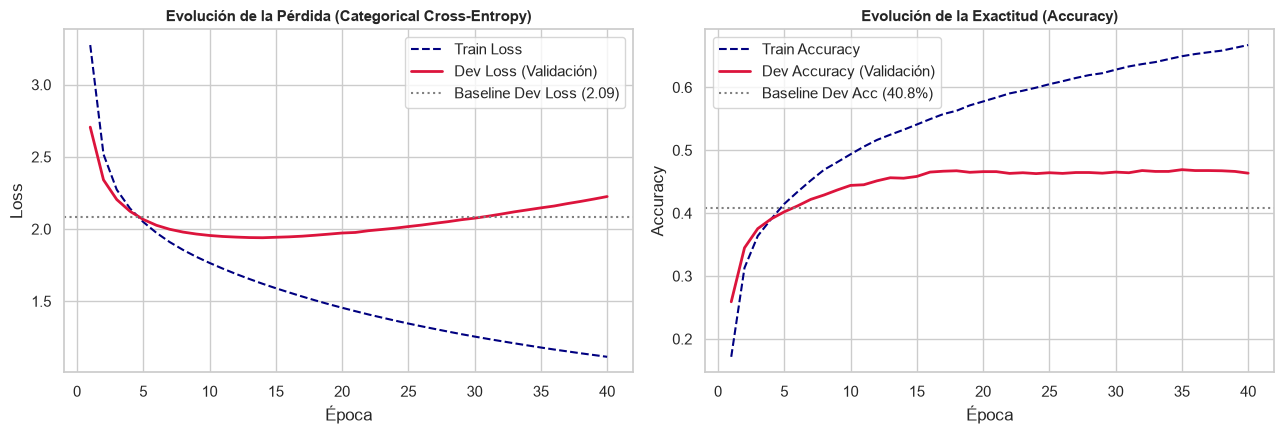

In [22]:
# ==============================================================================
# 7.2 CURVAS DE APRENDIZAJE: DIAGNÓSTICO GRÁFICO DE ALTA VARIANZA (Consigna 4.2.2)
# ==============================================================================
epocas = range(1, len(hist_mlp_base.history["loss"]) + 1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Curva de Pérdida (Loss)
axes[0].plot(epocas, hist_mlp_base.history["loss"], label="Train Loss", color="navy", linestyle="--")
axes[0].plot(epocas, hist_mlp_base.history["val_loss"], label="Dev Loss (Validación)", color="crimson", linewidth=2)
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label=f"Baseline Dev Loss ({loss_base_dev:.2f})")
axes[0].set_title("Evolución de la Pérdida (Categorical Cross-Entropy)", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend()

# Curva de Exactitud (Accuracy)
axes[1].plot(epocas, hist_mlp_base.history["accuracy"], label="Train Accuracy", color="navy", linestyle="--")
axes[1].plot(epocas, hist_mlp_base.history["val_accuracy"], label="Dev Accuracy (Validación)", color="crimson", linewidth=2)
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label=f"Baseline Dev Acc ({acc_base_dev*100:.1f}%)")
axes[1].set_title("Evolución de la Exactitud (Accuracy)", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend()

plt.tight_layout()
plt.show()


---
# 8. Consigna 4.2.3: Regularización y estudio de ablación

Las curvas de la sección 7.2 muestran **varianza alta**: la pérdida en Train baja hasta $1,11$, mientras que la de Dev llega a su mínimo en la época 14 ($1,94$) y después sube hasta $2,23$. La brecha Train–Dev es de unos $20$ pp con la semilla 42 ($21,19$ pp en promedio con 5 semillas, sección 8.2).

Implementamos 3 técnicas de regularización para combatir la varianza:
- **Dropout:** apaga neuronas al azar durante el entrenamiento, así la red no se apoya en combinaciones puntuales de Train.
- **L2:** penaliza los pesos grandes, lo que vuelve al modelo más suave y menos dependiente del ruido.
- **Early Stopping:** corta el entrenamiento cuando la pérdida en Dev deja de mejorar y se queda con los mejores pesos.

### Cómo las evaluamos
1. **Grilla en Dev (semilla 42, sección 8.1):** Dropout $\in \{0,1;\ 0,2;\ 0,3;\ 0,4\}$, L2 $\in \{10^{-5};\ 10^{-4};\ 10^{-3}\}$ y paciencia $\in \{5;\ 8\}$, siempre con Early Stopping (24 combinaciones). Elegimos la de **mayor accuracy en Dev** y, si empatan, la de menor pérdida. Como cada combinación usa una sola semilla, no tomamos como mejora real diferencias menores a ~0,5 pp (el desvío entre semillas).
2. **Ablación con 5 semillas (sección 8.2):** con los valores de la grilla, entrenamos cada técnica por separado y combinada, para ver cuánto aporta cada una:
   * **M1 — MLP Base:** sin regularización.
   * **M2 — Solo Early Stopping.**
   * **M3 — Solo L2.**
   * **M4 — Solo Dropout.**
   * **M5 — Combinado:** las tres técnicas juntas.

El **modelo ganador de la Etapa 2** es el de mayor accuracy media en Dev entre M1 y M5.

> **Aclaración:** como elegimos hiperparámetros y ganador mirando Dev, y Early Stopping usa Dev para decidir cuándo parar, el resultado en Dev es levemente optimista. La medición sin sesgo es la de Test, en la Etapa 5.


### 8.1 Grilla de hiperparámetros en Dev
La tabla muestra las 10 mejores combinaciones de las 24. También chequeamos si el valor elegido de cada hiperparámetro quedó en el borde de la grilla: si es así, el óptimo podría estar fuera del rango probado.


In [23]:
# ==============================================================================
# 8.1 GRILLA DE HIPERPARÁMETROS EN DEV (semilla 42)
# ==============================================================================
from itertools import product

GRILLA = {"dropout": [0.1, 0.2, 0.3, 0.4], "l2": [1e-5, 1e-4, 1e-3], "patience": [5, 8]}

def entrenar_mlp(seed, dropout=0.0, l2=0.0, use_es=False, patience=0, epochs=40):
    """Entrena un MLP con la configuración dada y devuelve (modelo, historial, tiempo en segundos)."""
    keras.utils.set_random_seed(seed)
    modelo = construir_mlp(k=K_OPTIMO, v_size=vocab_size, dropout_rate=dropout, l2_reg=l2)
    modelo.compile(
        optimizer=keras.optimizers.Adam(learning_rate=0.001),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"]
    )
    cbs = []
    if use_es:
        cbs.append(callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True))
    t0 = time.perf_counter()
    h = modelo.fit(X_train_oh, y_train_idx, validation_data=(X_dev_oh, y_dev_idx),
                   epochs=epochs, batch_size=128, callbacks=cbs, verbose=0)
    return modelo, h, time.perf_counter() - t0

filas_grilla = []
for d, l2, pac in product(GRILLA["dropout"], GRILLA["l2"], GRILLA["patience"]):
    modelo, h, _ = entrenar_mlp(SEED, dropout=d, l2=l2, use_es=True, patience=pac)
    loss_dev, acc_dev = modelo.evaluate(X_dev_oh, y_dev_idx, verbose=0)
    filas_grilla.append({"dropout": d, "l2": l2, "patience": pac, "epocas": len(h.history["loss"]),
                         "dev_acc": float(acc_dev), "dev_loss": float(loss_dev)})

# Criterio declarado: mayor accuracy en Dev; desempate por menor pérdida en Dev
df_grilla = (pd.DataFrame(filas_grilla)
             .sort_values(["dev_acc", "dev_loss"], ascending=[False, True])
             .reset_index(drop=True))
mejor = df_grilla.iloc[0]
DROPOUT_OPT, L2_OPT, PATIENCE_OPT = float(mejor["dropout"]), float(mejor["l2"]), int(mejor["patience"])

print("Mejor configuración (mayor accuracy en Dev, desempate por menor loss):")
print(f"  Dropout = {DROPOUT_OPT} | L2 = {L2_OPT:g} | Paciencia = {PATIENCE_OPT} | Dev Acc = {mejor['dev_acc']*100:.2f}%")
print(f"  ¿Dropout en el borde de la grilla? {DROPOUT_OPT in (min(GRILLA['dropout']), max(GRILLA['dropout']))}")
print(f"  ¿L2 en el borde de la grilla?      {L2_OPT in (min(GRILLA['l2']), max(GRILLA['l2']))}")
print(f"  Rango de accuracy en la grilla: {df_grilla['dev_acc'].min()*100:.2f}% – {df_grilla['dev_acc'].max()*100:.2f}%\n")
display(df_grilla.head(10).style.format({"dev_acc": "{:.2%}", "dev_loss": "{:.4f}", "l2": "{:g}"}))


Mejor configuración (mayor accuracy en Dev, desempate por menor loss):
  Dropout = 0.1 | L2 = 1e-05 | Paciencia = 5 | Dev Acc = 48.65%
  ¿Dropout en el borde de la grilla? True
  ¿L2 en el borde de la grilla?      True
  Rango de accuracy en la grilla: 40.56% – 48.65%



,dropout,l2,patience,epocas,dev_acc,dev_loss
0,0.100000,1e-05,5,32,48.65%,1.8665
1,0.100000,1e-05,8,35,48.65%,1.8665
2,0.200000,1e-05,5,40,47.95%,1.8974
3,0.200000,1e-05,8,40,47.95%,1.8974
4,0.100000,0.0001,5,29,47.36%,1.9359
5,0.100000,0.0001,8,32,47.36%,1.9359
6,0.200000,0.0001,5,36,47.26%,1.9666
7,0.200000,0.0001,8,39,47.26%,1.9666
8,0.300000,1e-05,8,40,45.76%,1.9203
9,0.300000,0.0001,5,39,45.14%,1.9878


In [24]:
# ==============================================================================
# 8.2 EJECUCIÓN DEL ESTUDIO DE ABLACIÓN CON 5 SEMILLAS (Consigna 4.2.3)
# ==============================================================================
configs_ablacion = {
    "MLP_Base": {"dropout": 0.0, "l2": 0.0, "use_es": False, "patience": 0},
    "MLP_Solo_EarlyStopping": {"dropout": 0.0, "l2": 0.0, "use_es": True, "patience": PATIENCE_OPT},
    "MLP_Solo_L2": {"dropout": 0.0, "l2": L2_OPT, "use_es": False, "patience": 0},
    "MLP_Solo_Dropout": {"dropout": DROPOUT_OPT, "l2": 0.0, "use_es": False, "patience": 0},
    "MLP_Combinado": {"dropout": DROPOUT_OPT, "l2": L2_OPT, "use_es": True, "patience": PATIENCE_OPT},
}

resultados_ablacion = {}
historiales_seed42 = {}
modelos_seed42 = {}

print("Iniciando entrenamiento del estudio de ablación (5 modelos x 5 semillas)...\n")

for nombre, cfg in configs_ablacion.items():
    corridas = []

    for s in SEEDS:
        modelo, h, t_run = entrenar_mlp(s, dropout=cfg["dropout"], l2=cfg["l2"],
                                        use_es=cfg["use_es"], patience=cfg["patience"])

        if s == 42:
            historiales_seed42[nombre] = h.history
            modelos_seed42[nombre] = modelo

        eval_tr  = modelo.evaluate(X_train_oh, y_train_idx, verbose=0)
        eval_dev = modelo.evaluate(X_dev_oh, y_dev_idx, verbose=0)

        loss_tr, acc_tr   = float(eval_tr[0]), float(eval_tr[1])
        loss_dev, acc_dev = float(eval_dev[0]), float(eval_dev[1])

        corridas.append({
            "seed": s, "time": t_run, "epocas": len(h.history["loss"]),
            "train_acc": acc_tr, "dev_acc": acc_dev, "brecha": acc_tr - acc_dev,
            "train_loss": loss_tr, "dev_loss": loss_dev, "dev_perp": np.exp(loss_dev)
        })

    df_c = pd.DataFrame(corridas)
    resultados_ablacion[nombre] = {
        "config": cfg,
        "params": int(modelo.count_params()),
        "tiempo_mean": df_c["time"].mean(),
        "epocas_mean": df_c["epocas"].mean(),
        "train_acc_mean": df_c["train_acc"].mean(), "train_acc_std": df_c["train_acc"].std(),
        "dev_acc_mean": df_c["dev_acc"].mean(),     "dev_acc_std": df_c["dev_acc"].std(),
        "dev_acc_min": df_c["dev_acc"].min(),
        "brecha_mean": df_c["brecha"].mean(),       "brecha_std": df_c["brecha"].std(),
        "dev_loss_mean": df_c["dev_loss"].mean(),   "dev_loss_std": df_c["dev_loss"].std(),
        "dev_perp_mean": df_c["dev_perp"].mean(),   "dev_perp_std": df_c["dev_perp"].std(),
        "corridas": corridas
    }
    print(f"  ✓ {nombre:<24} | Dev Acc: {resultados_ablacion[nombre]['dev_acc_mean']*100:.2f}% ± {resultados_ablacion[nombre]['dev_acc_std']*100:.2f}% | Brecha: {resultados_ablacion[nombre]['brecha_mean']*100:.2f} pp")

# Modelo ganador de la Etapa 2: criterio declarado en la sección 8 (mayor accuracy media en Dev)
GANADOR = max(resultados_ablacion, key=lambda n: resultados_ablacion[n]["dev_acc_mean"])
print(f"\nModelo ganador de la Etapa 2 (mayor accuracy media en Dev): {GANADOR}")

# Persistencia oficial en disco para la Etapa 5
registro_etapa2 = {
    "baseline": {
        "params": params_base, "tiempo": tiempo_base,
        "train_acc": float(acc_base_train), "dev_acc": float(acc_base_dev),
        "brecha": float(acc_base_train - acc_base_dev),
        "dev_loss": loss_base_dev, "dev_perp": perp_base_dev
    },
    "grilla": {"valores": GRILLA, "resultados": filas_grilla,
               "elegido": {"dropout": DROPOUT_OPT, "l2": L2_OPT, "patience": PATIENCE_OPT}},
    "ablacion": resultados_ablacion,
    "ganador": GANADOR
}
with open(os.path.join("..", "data", "processed", "resultados_modelos.json"), "w", encoding="utf-8") as f:
    json.dump(registro_etapa2, f, indent=2, default=float)

print("Resultados completos del estudio de ablación persistidos en data/processed/resultados_modelos.json")


Iniciando entrenamiento del estudio de ablación (5 modelos x 5 semillas)...



  ✓ MLP_Base                 | Dev Acc: 46.65% ± 0.46% | Brecha: 21.19 pp


  ✓ MLP_Solo_EarlyStopping   | Dev Acc: 45.76% ± 0.44% | Brecha: 9.21 pp


  ✓ MLP_Solo_L2              | Dev Acc: 46.69% ± 0.35% | Brecha: 21.23 pp


  ✓ MLP_Solo_Dropout         | Dev Acc: 48.44% ± 0.34% | Brecha: 15.45 pp


  ✓ MLP_Combinado            | Dev Acc: 47.56% ± 0.69% | Brecha: 10.61 pp

Modelo ganador de la Etapa 2 (mayor accuracy media en Dev): MLP_Solo_Dropout
Resultados completos del estudio de ablación persistidos en data/processed/resultados_modelos.json


TABLA COMPARATIVA DE MODELOS - ETAPA 2 (Evaluación en Dev con 5 Semillas; ★ = ganador)



,Parámetros,Tiempo Train (s),Train Accuracy,Dev Accuracy (μ ± σ),Dev Accuracy (peor semilla),Brecha Train-Dev,Dev Loss,Dev Perplejidad
Modelo,,,,,,,,
Baseline K=5 (Logística),"19,908",1.53,42.97%,40.83%,—,2.13 pp,2.0853,8.05
MLP Base (Sin regularizar),"53,536",9.04,67.85%,46.65% ± 0.46%,46.11%,21.19 pp,2.2376,9.38
MLP + Solo Early Stopping (paciencia 5),"53,536",4.77,54.97%,45.76% ± 0.44%,45.24%,9.21 pp,1.9199,6.82
MLP + Solo L2 (1e-05),"53,536",9.26,67.92%,46.69% ± 0.35%,46.28%,21.23 pp,2.2282,9.29
MLP + Solo Dropout (0.1) ★,"53,536",10.27,63.90%,48.44% ± 0.34%,48.06%,15.45 pp,1.9143,6.78
MLP Combinado (Drop + L2 + ES),"53,536",7.97,58.17%,47.56% ± 0.69%,46.94%,10.61 pp,1.8852,6.59


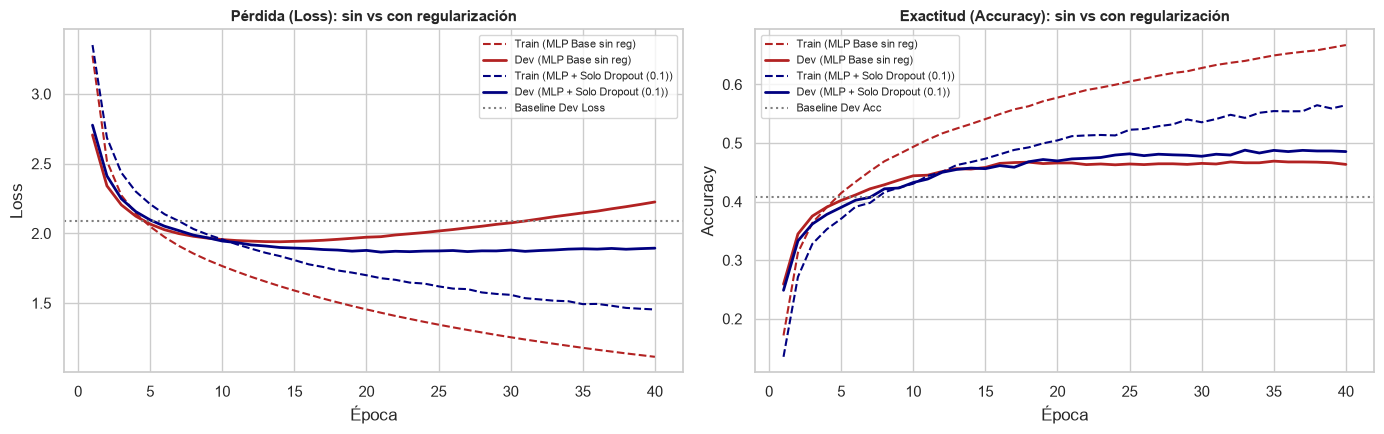

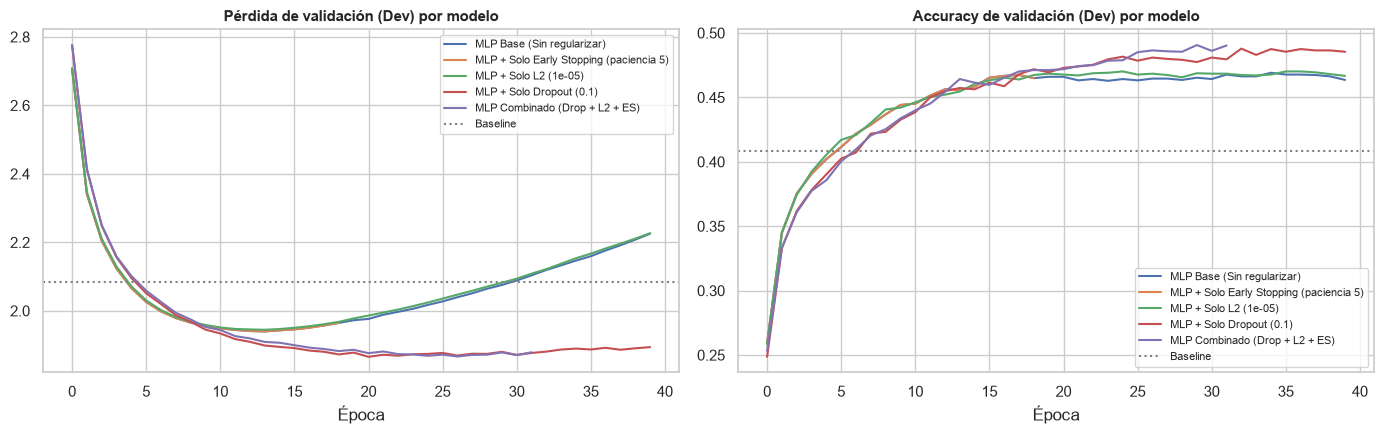

In [25]:
# ==============================================================================
# 8.3 TABLA SÍNTESIS DE ABLACIÓN Y CURVAS COMPARATIVAS (Consigna 4.2.3)
# ==============================================================================
filas_tabla = []
filas_tabla.append({
    "Modelo": "Baseline K=5 (Logística)",
    "Parámetros": f"{params_base:,}",
    "Tiempo Train (s)": f"{tiempo_base:.2f}",
    "Train Accuracy": f"{acc_base_train*100:.2f}%",
    "Dev Accuracy (μ ± σ)": f"{acc_base_dev*100:.2f}%",
    "Dev Accuracy (peor semilla)": "—",
    "Brecha Train-Dev": f"{(acc_base_train - acc_base_dev)*100:.2f} pp",
    "Dev Loss": f"{loss_base_dev:.4f}",
    "Dev Perplejidad": f"{perp_base_dev:.2f}"
})

nombres_vis = {
    "MLP_Base": "MLP Base (Sin regularizar)",
    "MLP_Solo_EarlyStopping": f"MLP + Solo Early Stopping (paciencia {PATIENCE_OPT})",
    "MLP_Solo_L2": f"MLP + Solo L2 ({L2_OPT:g})",
    "MLP_Solo_Dropout": f"MLP + Solo Dropout ({DROPOUT_OPT})",
    "MLP_Combinado": "MLP Combinado (Drop + L2 + ES)"
}

for k_m, v_m in resultados_ablacion.items():
    filas_tabla.append({
        "Modelo": nombres_vis[k_m] + (" ★" if k_m == GANADOR else ""),
        "Parámetros": f"{v_m['params']:,}",
        "Tiempo Train (s)": f"{v_m['tiempo_mean']:.2f}",
        "Train Accuracy": f"{v_m['train_acc_mean']*100:.2f}%",
        "Dev Accuracy (μ ± σ)": f"{v_m['dev_acc_mean']*100:.2f}% ± {v_m['dev_acc_std']*100:.2f}%",
        "Dev Accuracy (peor semilla)": f"{v_m['dev_acc_min']*100:.2f}%",
        "Brecha Train-Dev": f"{v_m['brecha_mean']*100:.2f} pp",
        "Dev Loss": f"{v_m['dev_loss_mean']:.4f}",
        "Dev Perplejidad": f"{v_m['dev_perp_mean']:.2f}"
    })

df_sintesis = pd.DataFrame(filas_tabla).set_index("Modelo")
print("TABLA COMPARATIVA DE MODELOS - ETAPA 2 (Evaluación en Dev con 5 Semillas; ★ = ganador)\n")
display(df_sintesis)

# Figura 1: con vs sin regularización, Train y Dev (semilla 42)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
h_base = historiales_seed42["MLP_Base"]
h_opt  = historiales_seed42[GANADOR]

ep_b = range(1, len(h_base["loss"]) + 1)
ep_o = range(1, len(h_opt["loss"]) + 1)

# Panel Loss
axes[0].plot(ep_b, h_base["loss"], label="Train (MLP Base sin reg)", color="firebrick", linestyle="--")
axes[0].plot(ep_b, h_base["val_loss"], label="Dev (MLP Base sin reg)", color="firebrick", linewidth=2)
axes[0].plot(ep_o, h_opt["loss"], label=f"Train ({nombres_vis[GANADOR]})", color="navy", linestyle="--")
axes[0].plot(ep_o, h_opt["val_loss"], label=f"Dev ({nombres_vis[GANADOR]})", color="navy", linewidth=2)
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label="Baseline Dev Loss")
axes[0].set_title("Pérdida (Loss): sin vs con regularización", fontsize=11, fontweight="bold")
axes[0].set_xlabel("Época")
axes[0].set_ylabel("Loss")
axes[0].legend(fontsize=8)

# Panel Accuracy
axes[1].plot(ep_b, h_base["accuracy"], label="Train (MLP Base sin reg)", color="firebrick", linestyle="--")
axes[1].plot(ep_b, h_base["val_accuracy"], label="Dev (MLP Base sin reg)", color="firebrick", linewidth=2)
axes[1].plot(ep_o, h_opt["accuracy"], label=f"Train ({nombres_vis[GANADOR]})", color="navy", linestyle="--")
axes[1].plot(ep_o, h_opt["val_accuracy"], label=f"Dev ({nombres_vis[GANADOR]})", color="navy", linewidth=2)
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label="Baseline Dev Acc")
axes[1].set_title("Exactitud (Accuracy): sin vs con regularización", fontsize=11, fontweight="bold")
axes[1].set_xlabel("Época")
axes[1].set_ylabel("Accuracy")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

# Figura 2: curvas de validación de los 5 modelos de la ablación
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for nombre, hist in historiales_seed42.items():
    axes[0].plot(hist["val_loss"], label=nombres_vis[nombre])
    axes[1].plot(hist["val_accuracy"], label=nombres_vis[nombre])
axes[0].axhline(loss_base_dev, color="gray", linestyle=":", label="Baseline")
axes[1].axhline(acc_base_dev, color="gray", linestyle=":", label="Baseline")
axes[0].set_title("Pérdida de validación (Dev) por modelo", fontsize=11, fontweight="bold")
axes[1].set_title("Accuracy de validación (Dev) por modelo", fontsize=11, fontweight="bold")
for ax in axes:
    ax.set_xlabel("Época")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.show()


### 8.4 ¿Dónde mejora el MLP?
Volvemos a usar `accuracy_por_tipo` y `explicar_prediccion` (secciones 6.3 y 6.4) para comparar el baseline con el modelo ganador. Usamos el modelo de la semilla 42, así que diferencias por tipo de un par de puntos no son concluyentes.


,Casos en Dev,% de Dev,Accuracy Baseline,Accuracy MLP_Solo_Dropout,Δ (pp)
espacio,514,17.8,0.8580,0.9105,5.25
vocal,817,28.4,0.3060,0.4002,9.42
consonante,1451,50.4,0.3280,0.4121,8.41
mayúscula,38,1.3,0.1842,0.1053,-7.89
puntuación/dígito,60,2.1,0.0333,0.0167,-1.66


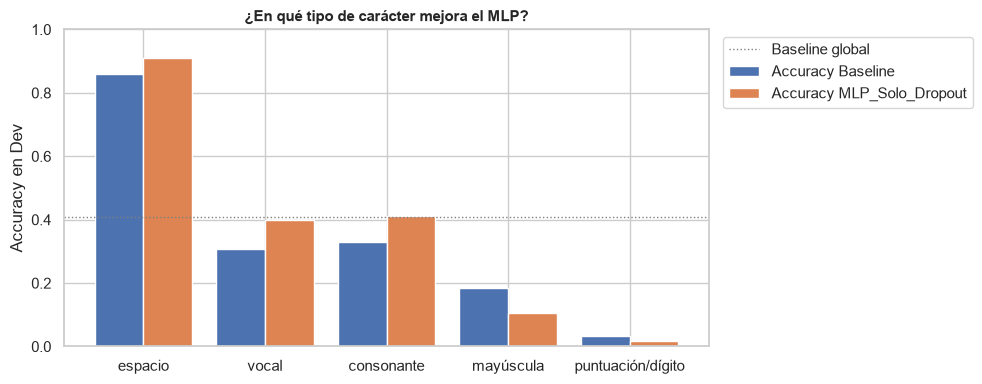

Causa (pre-etiqueta por reglas): Falta de cobertura (5-grama nuevo)
  [Baseline] contexto '...ad been striking. Af' | real 't' en el puesto 4 (P = 0.074)
     top-5: '<SP>' 0.503 | 'a' 0.102 | 'o' 0.100 | 't' 0.074 | 'l' 0.048
  [MLP_Solo_Dropout] contexto '...ad been striking. Af' | real 't' en el puesto 1 (P = 0.894)
     top-5: 't' 0.894 | 'c' 0.019 | 's' 0.018 | 'f' 0.014 | 'a' 0.014

Causa (pre-etiqueta por reglas): Ruido irreducible (Error Bayes)
  [Baseline] contexto '... wrote a quaint and ' | real 'a' en el puesto 4 (P = 0.090)
     top-5: 't' 0.147 | 'w' 0.140 | 's' 0.095 | 'a' 0.090 | 'h' 0.059
  [MLP_Solo_Dropout] contexto '... wrote a quaint and ' | real 'a' en el puesto 6 (P = 0.064)
     top-5: 't' 0.188 | 's' 0.113 | 'w' 0.092 | 'm' 0.078 | 'b' 0.066

Causa (pre-etiqueta por reglas): Sesgo (Underfitting)
  [Baseline] contexto '...tone above with a na' | real 's' en el puesto 3 (P = 0.088)
     top-5: 't' 0.160 | 'd' 0.127 | 's' 0.088 | 'l' 0.087 | '<SP>' 0.086
  [MLP_So

  [MLP_Solo_Dropout] contexto '...ersons on the settle' | real ',' en el puesto 2 (P = 0.077)
     top-5: '<SP>' 0.786 | ',' 0.077 | 's' 0.033 | '.' 0.030 | ';' 0.018



In [26]:
# ==============================================================================
# 8.4 BASELINE VS MODELO GANADOR: ACCURACY POR TIPO Y EXPLICACIÓN DE CASOS
# ==============================================================================
modelo_ganador = modelos_seed42[GANADOR]

def proba_mlp(contextos, modelo=modelo_ganador):
    """Matriz (n, |V|) de probabilidades del MLP, en el orden de char2idx."""
    X_oh, _ = extraer_tensores_onehot(contextos, [" "] * len(contextos), K_OPTIMO, char2idx, vocab_size)
    return modelo.predict(X_oh, verbose=0)

y_pred_dev_mlp = [idx2char[i] for i in proba_mlp(X_dev).argmax(axis=1)]

df_tipos = df_tipos_base.copy()
df_tipos[f"Accuracy {GANADOR}"] = pd.Series(accuracy_por_tipo(y_pred_dev_mlp)).reindex(TIPOS_CHAR).round(4)
df_tipos["Δ (pp)"] = ((df_tipos[f"Accuracy {GANADOR}"] - df_tipos["Accuracy Baseline"]) * 100).round(2)
display(df_tipos)

# Gráfico de barras agrupadas por tipo
ax = df_tipos[["Accuracy Baseline", f"Accuracy {GANADOR}"]].plot.bar(figsize=(10, 4), width=0.8, rot=0)
ax.axhline(acc_base_dev, color="gray", ls=":", lw=1, label="Baseline global")
ax.set_ylim(0, 1)
ax.set_ylabel("Accuracy en Dev")
ax.set_xlabel("")
ax.set_title("¿En qué tipo de carácter mejora el MLP?", fontsize=11, fontweight="bold")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

# Mismos casos de la sección 6.4, ahora con ambos modelos
for _, fila in casos_ejemplo.iterrows():
    print(f"Causa (pre-etiqueta por reglas): {fila['causa_teorica']}")
    explicar_prediccion(proba_baseline, X_dev[fila["dev_idx"]], fila["y_real"], "Baseline")
    explicar_prediccion(proba_mlp, X_dev[fila["dev_idx"]], fila["y_real"], GANADOR)
    print()


In [27]:
# ==============================================================================
# 8.5 ESTIMACIÓN DEL SESGO EVITABLE DEL BASELINE (ver advertencia de la sección 6.2)
# ==============================================================================
err_tr_base    = 1 - acc_base_train
err_tr_mlpbase = 1 - resultados_ablacion["MLP_Base"]["train_acc_mean"]
err_tr_ganador = 1 - resultados_ablacion[GANADOR]["train_acc_mean"]
mejora_dev     = resultados_ablacion[GANADOR]["dev_acc_mean"] - acc_base_dev

print(f"Error de Train del baseline:                 {err_tr_base*100:.2f}%")
print(f"Error de Train del MLP sin regularizar:      {err_tr_mlpbase*100:.2f}%  (memoriza: no sirve como cota)")
print(f"Error de Train del modelo ganador:           {err_tr_ganador*100:.2f}%")
print(f"\nReducción del error de Train con el ganador: {(err_tr_base - err_tr_ganador)*100:.2f} pp")
print(f"Mejora en Dev del ganador sobre el baseline: {mejora_dev*100:.2f} pp")


Error de Train del baseline:                 57.03%
Error de Train del MLP sin regularizar:      32.15%  (memoriza: no sirve como cota)
Error de Train del modelo ganador:           36.10%

Reducción del error de Train con el ganador: 20.93 pp
Mejora en Dev del ganador sobre el baseline: 7.61 pp


### 8.6 Conclusiones de la Etapa 2

1. **Mejora sobre el baseline.** El ganador es el **MLP + Dropout 0,1**: $48,44\% \pm 0,34\%$ en Dev (peor semilla: $48,06\%$), **$+7,61$ pp sobre el baseline** ($40,83\%$). La mejora supera el desvío entre semillas y el margen de error de Dev ($\approx \pm 1,8$ pp). Como la entrada es la misma, la atribuimos principalmente a la red.

2. **De sesgo a varianza.** El baseline tiene error alto en Train ($57,03\%$) y brecha chica ($2,13$ pp): **sesgo alto**. El MLP sin regularizar baja el error de Train a $32,15\%$ pero abre una brecha de $21,19$ pp: **varianza alta**. La regularización achica esa brecha ($15,45$ pp con Dropout; $9,21$ pp con Early Stopping).

3. **Sesgo corregible del baseline (sección 8.5).** El ganador baja el error de Train en $20,93$ pp y el de Dev en $7,61$ pp. Tomamos $7,61$ pp como estimación conservadora y $20,93$ pp como optimista (incluye algo de memorización). No es una cota exacta, porque no conocemos el error mínimo posible de esta tarea.

4. **Qué aporta cada técnica (sección 8.2):**
   * **Dropout ($0,1$):** es la única técnica que, sola, mejora la accuracy de forma clara ($+1,79$ pp sobre el MLP Base) y baja la pérdida en Dev de $2,24$ a $1,91$.
   * **L2 ($10^{-5}$):** no cambia nada ($46,69\%$ vs $46,65\%$, misma brecha). En la grilla, cuanto más L2, peor: accuracy media de $46,1\%$ con $10^{-5}$, $45,5\%$ con $10^{-4}$ y $42,7\%$ con $10^{-3}$.
   * **Early Stopping solo:** achica la brecha a $9,21$ pp y baja la pérdida a $1,92$, pero **empeora** la accuracy ($45,76\%$, $-0,89$ pp). Corta según la pérdida en Dev, y en el MLP Base (semilla 42) la pérdida toca su mínimo en la época 14 ($45,56\%$ de accuracy) mientras la accuracy sigue subiendo hasta la época 35 ($46,91\%$). Por eso frena (en la época 18–19) cuando el modelo todavía podía acertar más.
   * **Combinado:** tiene la **menor pérdida** ($1,885$) y la **menor perplejidad** ($6,59$), con brecha de $10,61$ pp, pero su accuracy ($47,56\% \pm 0,69\%$) queda debajo de solo Dropout. Con la métrica oficial gana Dropout; para generar texto, donde importan las probabilidades y no solo el top-1, el combinado es un candidato para la Etapa 3.

5. **Acertar más no es lo mismo que predecir mejor las probabilidades.** El MLP sin regularizar acierta más que el baseline ($46,65\%$ vs $40,83\%$) pero tiene **peor perplejidad** ($9,38$ vs $8,05$): cuando se equivoca, le da una probabilidad muy baja al carácter real. Todas las variantes con Dropout o Early Stopping quedan con mejor perplejidad que el baseline.

6. **Dónde mejora el MLP (sección 8.4).** Mejora en espacios ($+5,25$ pp), vocales ($+9,42$ pp) y consonantes ($+8,41$ pp), que son el $96,6\%$ de Dev. En mayúsculas y puntuación baja ($-7,89$ y $-1,66$ pp), pero son 38 y 60 casos: la diferencia es de 3 y 1 aciertos, no alcanza para sacar conclusiones. En los ejemplos, el error de 5-grama nuevo (`Af` → `t`), que el baseline ponía 4.º con $P = 0,074$, el MLP lo acierta con $P = 0,894$: generaliza a combinaciones que no vio. El de ruido irreducible (`and ` → `a`) sigue fallando en los dos, como se espera.

7. **Límite de la grilla.** Dropout $0,1$ y L2 $10^{-5}$ son los valores **más bajos** de la grilla, así que el mejor Dropout podría estar por debajo de $0,1$. La paciencia no influyó: con 5 y con 8 dio exactamente lo mismo, porque en 14 de las 24 corridas Early Stopping no llegó a activarse antes de la época 40 y en las demás `restore_best_weights` recupera la misma época.

8. **Dev es levemente optimista.** Elegimos hiperparámetros y ganador mirando Dev, y Early Stopping usa Dev para parar. La medición sin sesgo se hará una única vez sobre Test, en la Etapa 5.


### 8.7 Registro de experimentos que no funcionaron
Documentamos también lo que no funcionó, porque muestra qué no aporta en este problema. Todos los valores son accuracy en Dev.

| Experimento | Resultado en Dev | Conclusión |
|---|---|---|
| Solo L2 ($10^{-5}$), 5 semillas | $46,69\% \pm 0,35\%$ (MLP Base: $46,65\%$) | No reduce la brecha ni mejora la accuracy. |
| L2 más fuerte en la grilla ($10^{-3}$) | entre $40,56\%$ y $44,31\%$ | Empeora la accuracy en todas las combinaciones; con Dropout $0,4$ cae al nivel del baseline ($40,56\%$). |
| Dropout alto en la grilla ($0,4$) | entre $40,56\%$ y $42,57\%$ | Demasiada regularización para una red de 53.536 parámetros con 12.780 muestras. |
| Solo Early Stopping, 5 semillas | $45,76\% \pm 0,44\%$ | Reduce la brecha pero baja la accuracy: corta por `val_loss`, no por accuracy. |
| Combinado (Dropout + L2 + ES), 5 semillas | $47,56\% \pm 0,69\%$ | Sumar técnicas no suma mejoras. Probablemente L2 y ES recortan capacidad que Dropout ya controla. |
| Paciencia 8 vs 5 en la grilla | resultados idénticos | La paciencia no fue un hiperparámetro relevante en 40 épocas. |
| Versión anterior de la ablación (Dropout $0,2$, L2 $10^{-4}$, fijados sin grilla en el código) | combinado $46,91\%$; solo Dropout $47,67\%$ | Llamar "óptimo" al combinado era incorrecto; motivó la grilla explícita y el criterio de selección declarado. |


---
# 9. Síntesis y checklist de la Etapa 2
Estado de cada requisito de la consigna antes de pasar a la Etapa 3.


In [28]:
# ==============================================================================
# 9.1 CHECKLIST OFICIAL DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)
# ==============================================================================
r_gan = resultados_ablacion[GANADOR]
delta_gan = (r_gan["dev_acc_mean"] - acc_base_dev) * 100

print("=" * 80)
print("CHECKLIST DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)")
print("=" * 80)
print(f"  [ ] 4.2.1 Análisis de errores manual: 50 muestras pre-etiquetadas por reglas; falta la revisión manual.")
print(f"  [x] 4.2.1 Diagnóstico de sesgo vs varianza del baseline (brecha Train - Dev = {(acc_base_train - acc_base_dev)*100:.2f} pp).")
print(f"  [x] 4.2.1 Accuracy por tipo de carácter y explicación de predicciones.")
print(f"  [x] 4.2.2 Arquitectura MLP en tf.keras: 3 capas ocultas (128-64-32, {resultados_ablacion['MLP_Base']['params']:,} parámetros).")
print(f"  [x] 4.2.2 Funciones documentadas: ReLU, Softmax, Loss Categorical Cross-Entropy y Optimizador Adam.")
print(f"  [x] 4.2.2 Curvas de aprendizaje (Loss y Accuracy) en Train y Dev.")
print(f"  [x] 4.2.3 Regularización: 3 técnicas (Dropout {DROPOUT_OPT}, L2 {L2_OPT:g}, Early Stopping con paciencia {PATIENCE_OPT}) elegidas con una grilla en Dev.")
print(f"  [x] 4.2.3 Ablación con 5 semillas, curvas con y sin regularización.")
print(f"  [x] 4.2.3 Mejora sobre el Baseline en Dev: {GANADOR} = {r_gan['dev_acc_mean']*100:.2f}% ± {r_gan['dev_acc_std']*100:.2f}% ({delta_gan:+.2f} pp).")
print(f"  [x] Parámetros y tiempos registrados en resultados_modelos.json para la Etapa 5.")
print(f"  [x] Conjunto Test estrictamente preservado sin evaluar hasta la Etapa 5.")
print("=" * 80)


CHECKLIST DE CUMPLIMIENTO - ETAPA 2 (UNAB 2026)
  [ ] 4.2.1 Análisis de errores manual: 50 muestras pre-etiquetadas por reglas; falta la revisión manual.
  [x] 4.2.1 Diagnóstico de sesgo vs varianza del baseline (brecha Train - Dev = 2.13 pp).
  [x] 4.2.1 Accuracy por tipo de carácter y explicación de predicciones.
  [x] 4.2.2 Arquitectura MLP en tf.keras: 3 capas ocultas (128-64-32, 53,536 parámetros).
  [x] 4.2.2 Funciones documentadas: ReLU, Softmax, Loss Categorical Cross-Entropy y Optimizador Adam.
  [x] 4.2.2 Curvas de aprendizaje (Loss y Accuracy) en Train y Dev.
  [x] 4.2.3 Regularización: 3 técnicas (Dropout 0.1, L2 1e-05, Early Stopping con paciencia 5) elegidas con una grilla en Dev.
  [x] 4.2.3 Ablación con 5 semillas, curvas con y sin regularización.
  [x] 4.2.3 Mejora sobre el Baseline en Dev: MLP_Solo_Dropout = 48.44% ± 0.34% (+7.61 pp).
  [x] Parámetros y tiempos registrados en resultados_modelos.json para la Etapa 5.
  [x] Conjunto Test estrictamente preservado sin eva